# Power spectra estimation: QML vs NaMaster vs heracles (DR1 North, MetaCal)

The TR1 South analysis (`TR1/TR1_south_power_spectra_and_covariance_estimation.ipynb`) repeated on the Euclid DR1
**North** field, with the **MetaCal** shear catalogue (`dr1_dps_tiles_v6/metacal_only`, B-Mode Tiger Team release; see
`data/README_v6.md`). All tomographic bins are combined. South and North are analysed separately: they were calibrated in
separate shear runs and use different ground-based photometry.

Differences from TR1 South:
- **Input:** one Parquet file per tile instead of one FITS catalogue. The ~10⁸ galaxies don't fit in memory, so the
  catalogue is read one tile at a time (`dr1_tools.py`), both for the pixel sums below and for heracles.
- **Pixel cut on noise, not coverage.** DR1 comes with no coverage map. What hurt QML in TR1 was the extra noise of
  sparsely populated pixels, so pixels are cut directly on their effective galaxy number
  $N_{\rm eff,pix} = (\sum w)^2/\sum w^2$: a pixel is kept if $N_{\rm eff,pix}$ is at least `neff_min_frac` (0.5) of
  the field's median, i.e. its noise is at most twice the typical value.
- **With and without the cut:** QML and heracles are both run on all pixels with galaxies and on the kept pixels only.
- **Catalogue columns:** `SHE_METACAL_{RA,DEC}`, `SHE_METACAL_E{1,2}_CORRECTED`, `SHE_METACAL_WEIGHT_CORRECTED` (the
  calibrated weight; galaxies with zero calibrated weight are dropped), and `PHZ_MODE_1` for the redshift distribution
  (DR1 has no `PHZ_MEDIAN`).

⚠︎ The DR1 data are unblinded and restricted to the B-Mode Tiger Team.

In [1]:
import os
import sys
import time
import shutil
import subprocess

import numpy as np
from scipy.stats import chi2 as chi2_dist
import healpy as hp
import pymaster as nmt
import heracles
import heracles.healpy

from matplotlib import pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
import seaborn as sns
import matplotlib

matplotlib.use('Agg')
plt.rcParams['text.usetex'] = False
sns.set(font_scale=1.25, rc={'text.usetex': False, 'figure.dpi': 300})

In [2]:
%matplotlib inline

In [3]:
# The notebook runs from DR1/
dr1_dir = os.path.abspath(os.getcwd())
root_filepath = os.path.dirname(os.path.dirname(dr1_dir))
sys.path.append(root_filepath)
sys.path.append(dr1_dir)

from python.lib.CppInterface.GeneratePowerSpectra import PowerSpec
from python.lib.CppInterface.GenerateCppConstants import generate_constants_h
from python.lib.CppInterface.CppLib import CppLib
import dr1_tools

## Settings

The same as TR1 South: $N_{\rm side}=64$, $\ell_{\max}=150$, 10 Monte Carlo maps for the Fisher matrix, and
bandpowers of width $\Delta\ell=20$ from $\ell=10$.

In [4]:
field = 'north'
field_label = 'DR1 North'
method = 'metacal'          # shear catalogue: 'metacal' or 'lensmc'
method_label = 'MetaCal'

n_side = 64
n_pix = 12 * n_side * n_side
l_max_full = 150
ells_full = np.arange(2, l_max_full + 1)
n_ell_full = len(ells_full)
ells = ells_full
num_maps = 10

# Keep pixels whose effective galaxy number is at least this fraction of the field median (noise <= 2x typical)
neff_min_frac = 0.5

tile_dir = f'{dr1_dir}/data/{method}_only'
data_dir = f'{dr1_dir}/data/{method}/{field}'
fig_dir = f'{dr1_dir}/figures/{method}/{field}'
os.makedirs(f'{data_dir}/masks', exist_ok=True)
os.makedirs(fig_dir, exist_ok=True)

tiles = dr1_tools.field_tiles(tile_dir, field, method, f'{dr1_dir}/data/tile_dec_{method}.json')
print(f'{len(tiles)} tiles in the {field} field')

1951 tiles in the north field


## Per-pixel sums from the catalogue

One pass over the field's tiles gives, for every $N_{\rm side}=64$ pixel, the galaxy count, $\sum w$, $\sum w^2$,
$\sum w e_1$, $\sum w e_2$ and $\sum w(e_1^2+e_2^2)$, plus the weighted photo-z histogram. Everything QML and
NaMaster need (maps, noise level, pixel cut, $n(z)$) follows from these. They are cached, as the pass takes a few
minutes.

In [5]:
z_edges = np.linspace(0.0, 3.0, 501)
sums_path = f'{data_dir}/pixel_sums_N{n_side}.npz'
if os.path.exists(sums_path):
    s = np.load(sums_path)
    sums, redshift_dist = {k: s[k] for k in ['n', 'sw', 'sw2', 'swe1', 'swe2', 'swee']}, s['nz']
else:
    start = time.time()
    sums, redshift_dist = dr1_tools.pixel_sums(tiles, method, n_side, z_edges)
    np.savez(sums_path, nz=redshift_dist, **sums)
    print(f'read {len(tiles)} tiles in {time.time() - start:.0f} s')
print(f'{sums["n"].sum():.4g} galaxies (TOM_BIN_ID >= 1)')

2.781e+07 galaxies (TOM_BIN_ID >= 1)


## Pixel cut on noise

At $N_{\rm side}=64$ each pixel is about 55′ across. Pixels along the field edges and the gaps between survey stripes
are only partly covered, so they hold few galaxies. A pixel's noise variance is $\sigma_\epsilon^2/N_{\rm eff,pix}$,
while QML assumes one value for every pixel. Pixels with $N_{\rm eff,pix}$ below half the field median are removed.

In [6]:
has_gal = sums['sw'] > 0
neff_pix = np.divide(sums['sw'] ** 2, sums['sw2'], out=np.zeros(n_pix), where=has_gal)
neff_median = np.median(neff_pix[has_gal])
neff_ratio = neff_pix / neff_median

mask = neff_ratio >= neff_min_frac       # kept pixels
mask_nocut = has_gal                     # every pixel with galaxies
removed = has_gal & ~mask
f_sky = mask.mean()
print(f'pixels with galaxies: {has_gal.sum()};  kept (N_eff >= {neff_min_frac:g} x median = {neff_min_frac * neff_median:.0f}): '
      f'{mask.sum()};  removed: {removed.sum()} ({100 * removed.sum() / has_gal.sum():.0f}% of pixels, '
      f'{100 * sums["n"][removed].sum() / sums["n"].sum():.1f}% of galaxies)')
print(f'f_sky kept: {100 * f_sky:.3f} %,  no cut: {100 * mask_nocut.mean():.3f} %')

mask_filepath = f'{data_dir}/masks/SkyMask_{field}_N{n_side}_neff{neff_min_frac:g}.fits'
mask_nocut_filepath = f'{data_dir}/masks/SkyMask_{field}_N{n_side}_nocut.fits'
hp.write_map(mask_filepath, mask.astype(float), overwrite=True, fits_IDL=False, dtype=np.float64)
hp.write_map(mask_nocut_filepath, mask_nocut.astype(float), overwrite=True, fits_IDL=False, dtype=np.float64)

pixels with galaxies: 711;  kept (N_eff >= 0.5 x median = 23471): 533;  removed: 178 (25% of pixels, 5.3% of galaxies)
f_sky kept: 1.084 %,  no cut: 1.447 %


/tmp/ipykernel_42546/1804569545.py:27: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


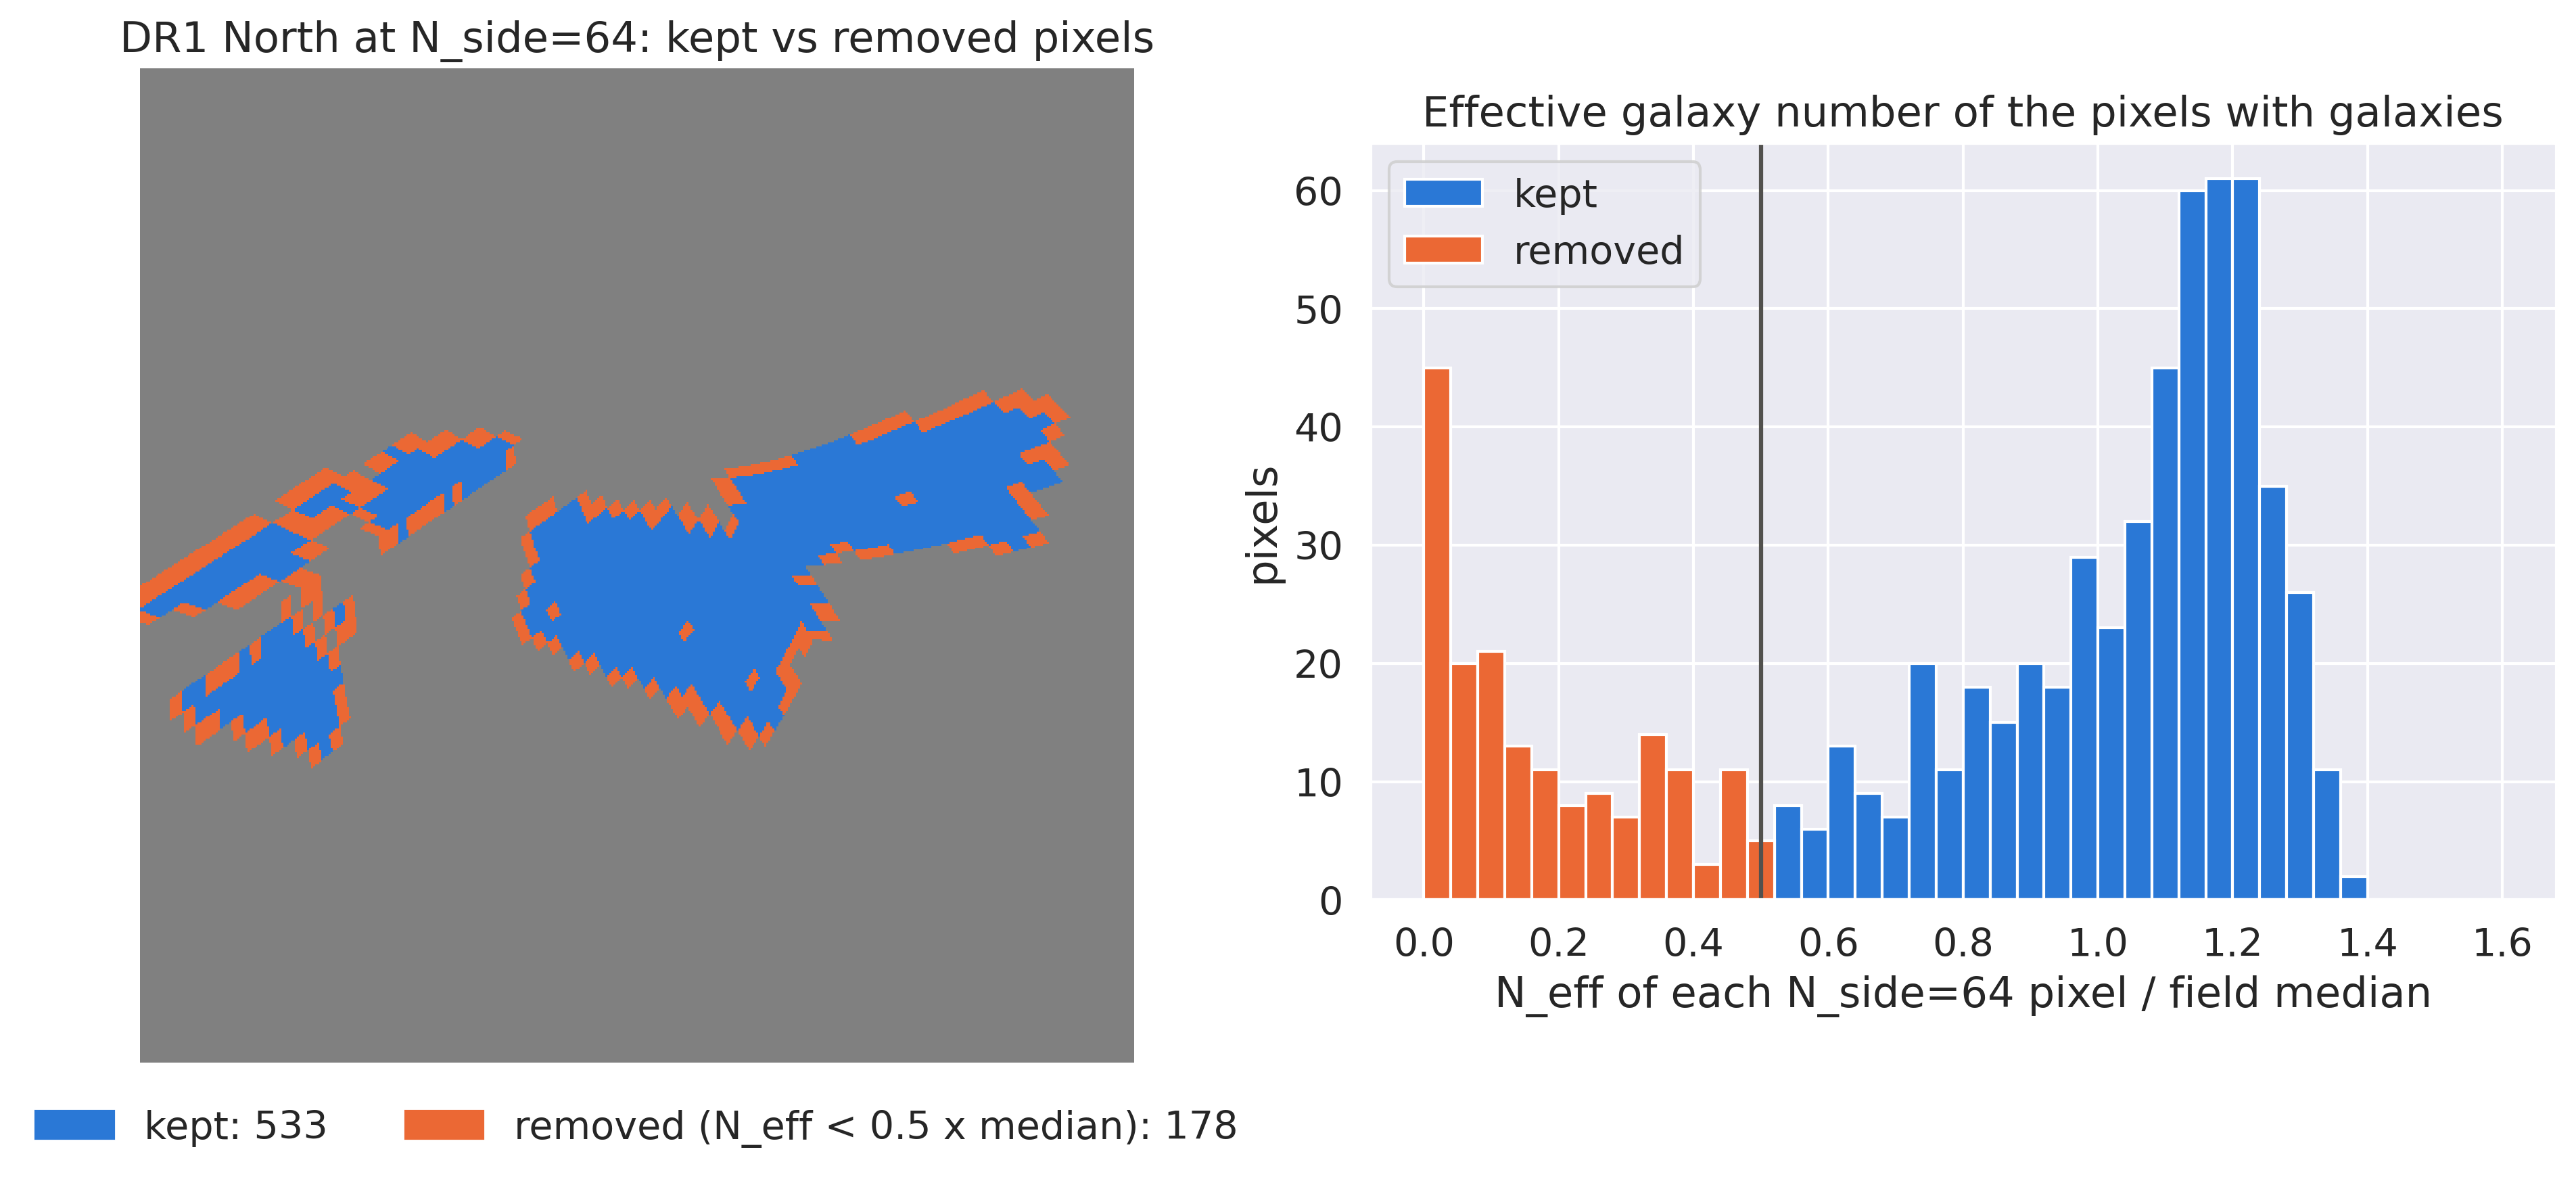

In [7]:
BLUE, ORANGE, GREEN, INK = '#2a78d6', '#eb6834', '#1baf7a', '#52514e'

# Centre and size of the field, for a zoomed (gnomonic) view
vec = np.array(hp.pix2vec(n_side, np.where(has_gal)[0]))
centre = vec.mean(axis=1) / np.linalg.norm(vec.mean(axis=1))
radius_deg = np.degrees(np.arccos(np.clip(centre @ vec, -1, 1)).max())
lon_c, lat_c = hp.vec2ang(centre, lonlat=True)

state = np.full(n_pix, hp.UNSEEN)
state[mask], state[removed] = 0, 1
fig = plt.figure(figsize=(13, 5))
hp.gnomview(state, rot=(lon_c[0], lat_c[0]), xsize=500, reso=2.2 * radius_deg * 60 / 500, fig=fig, sub=(1, 2, 1),
            cmap=ListedColormap([BLUE, ORANGE]), min=0, max=1, cbar=False, notext=True,
            title=f'{field_label} at N_side={n_side}: kept vs removed pixels')
plt.gca().legend(handles=[Patch(color=BLUE, label=f'kept: {mask.sum()}'),
                          Patch(color=ORANGE, label=f'removed (N_eff < {neff_min_frac:g} x median): {removed.sum()}')],
                 loc='lower center', bbox_to_anchor=(0.5, -0.12), ncol=2, frameon=False)

ax = fig.add_subplot(1, 2, 2)
bins_r = np.linspace(0, 1.6, 41)
ax.hist(np.clip(neff_ratio[mask], 0, 1.6), bins=bins_r, color=BLUE, label='kept')
ax.hist(neff_ratio[removed], bins=bins_r, color=ORANGE, label='removed')
ax.axvline(neff_min_frac, color=INK, lw=1.5)
ax.set_xlabel('N_eff of each N_side=64 pixel / field median'); ax.set_ylabel('pixels')
ax.set_title('Effective galaxy number of the pixels with galaxies')
ax.legend()
plt.tight_layout()
fig.savefig(f'{fig_dir}/pixels.png', dpi=200, bbox_inches='tight')
plt.show()

## Bandpower binning

Uniform bands of width $\Delta\ell=20$ from $\ell=10$, as for TR1 South, the last band absorbing the remainder. The
binning matrix is applied to the QML Fisher matrix and $y_\ell$ *before* inverting. NaMaster and heracles use the same
edges.

In [8]:
bandpower_width = 20
ell_bp_edges = np.r_[np.arange(10, l_max_full + 1 - bandpower_width, bandpower_width), l_max_full + 1]
ell_bp_ini, ell_bp_end = ell_bp_edges[:-1], ell_bp_edges[1:]
n_bands = len(ell_bp_ini)

# 0/1 indicator: F_b = W F W^T and y_b = W y for a flat bandpower model
bin_matrix = np.zeros((n_bands, n_ell_full))
for b in range(n_bands):
    bin_matrix[b, (ells_full >= ell_bp_ini[b]) & (ells_full < ell_bp_end[b])] = 1.0
bin_matrix_EB = np.zeros((2 * n_bands, 2 * n_ell_full))
bin_matrix_EB[:n_bands, :n_ell_full] = bin_matrix
bin_matrix_EB[n_bands:, n_ell_full:] = bin_matrix

bins = nmt.NmtBin.from_edges(ell_bp_ini, ell_bp_end)
ell_bp = bins.get_effective_ells()
# Theory curves are drawn over the bandpower range only (no data below l = 10)
ells_plot = ells[ells >= ell_bp_edges[0]]

## Fiducial power spectrum

CCL with the TR1 fiducial cosmology and the weighted `PHZ_MODE_1` distribution of the field's galaxies. Comparisons
with theory use the signal times the HEALPix pixel window $w_\ell^2$, since the maps are pixel averages.

In [9]:
fiducial_cosmology = {'h': 0.7, 'Omega_c': 0.27, 'Omega_b': 0.045, 'sigma8': 0.75, 'n_s': 0.96,
                      'm_nu': 0.0, 'T_CMB': 2.7255, 'w0': -1.0, 'wa': 0.0}
redshift_range = (z_edges[:-1] + z_edges[1:]) / 2
cl_file_path = f'{data_dir}/TheorySpectra_{field}_N{n_side}.dat'
pow_spec = PowerSpec(n_side, fiducial_cosmology, redshift_range, redshift_dist, cl_file_path)
pow_spec.compute_power_spec()

pixwin2 = hp.pixwin(n_side, lmax=len(pow_spec.cl_EE) - 1) ** 2
cl_EE_signal_pw = pow_spec.cl_EE * pixwin2
print(f'weighted mean photo-z: {np.sum(redshift_range * redshift_dist) / redshift_dist.sum():.2f}')

Evaluating the theory Cl values using CCL
Saved the power spectrum to /workspaces/QML/DR1/data/metacal/north/TheorySpectra_north_N64.dat
weighted mean photo-z: 0.93


## Noise level

From the galaxies in kept pixels, as for TR1: the weighted per-component shape scatter $\sigma_\epsilon^2$, the
effective number $n_{\rm eff}=(\sum w)^2/\sum w^2$, the shot-noise power $C^N=\sigma_\epsilon^2/\bar n_{\rm eff}$ and
QML's per-pixel noise variance. The no-cut QML run gets its own values from all pixels with galaxies.

In [10]:
arcmin2_per_steradian = (180 / np.pi) ** 2 * 3600


def noise_level(sel):
    # sigma_e^2, effective density per arcmin^2, shot-noise C_ell and QML per-pixel noise variance for pixels sel
    sw, sw2, swee = sums['sw'][sel].sum(), sums['sw2'][sel].sum(), sums['swee'][sel].sum()
    sigma_e2 = swee / (2 * sw)
    n_eff = sw ** 2 / sw2
    area = sel.sum() / n_pix * 4 * np.pi
    return sigma_e2, n_eff / (area * arcmin2_per_steradian), sigma_e2 / (n_eff / area), sigma_e2 / (n_eff / sel.sum())


sigma_e2, avg_gal_den, cl_noise, noise_var = noise_level(mask)
_, _, cl_noise_nocut, noise_var_nocut = noise_level(mask_nocut)
print(f'kept pixels: sigma_e = {np.sqrt(sigma_e2):.3f}, n_eff = {avg_gal_den:.2f} /arcmin^2, '
      f'C_noise = {cl_noise:.3e}, noise_var = {noise_var:.3e}')
print(f'no cut:      C_noise = {cl_noise_nocut:.3e}, noise_var = {noise_var_nocut:.3e}')

kept pixels: sigma_e = 0.279, n_eff = 16.33 /arcmin^2, C_noise = 4.041e-10, noise_var = 1.581e-06
no cut:      C_noise = 5.105e-10, noise_var = 1.997e-06


## Shear maps

Weighted mean shear per pixel. As for TR1, $\gamma_1 = -e_1$ and $\gamma_2 = e_2$ to match the catalogue's convention
to HEALPix's; the checks below test it for this catalogue. A wrong sign of $e_1$ would rotate about half the $E$-mode power into $B$. The NaMaster check below
is clear on the larger South field (with the wrong sign the $B$-modes take up about half the $E$ signal). On the North field
NaMaster's low-$\ell$ errors are too large for it to be decisive; there, `QML (BB - N) / EE theory` in the Numbers
section is the check: a few percent with the right sign, ~0.5 with the wrong one.

In [11]:
def shear_maps(sel, e1_sign=-1):
    g1 = np.divide(e1_sign * sums['swe1'], sums['sw'], out=np.zeros(n_pix), where=has_gal) * sel
    g2 = np.divide(sums['swe2'], sums['sw'], out=np.zeros(n_pix), where=has_gal) * sel
    return g1, g2


# Sign check: NaMaster on the kept pixels, noise removed, summed over bands with l < 70 (signal-dominated)
low_bands = ell_bp < 70
for e1_sign in (-1, 1):
    cl = nmt.compute_full_master(nmt.NmtField(mask, list(shear_maps(mask, e1_sign)), lmax=bins.lmax),
                                 nmt.NmtField(mask, list(shear_maps(mask, e1_sign)), lmax=bins.lmax), bins)
    print(f'gamma_1 = {e1_sign:+d} x e1:  sum over l<70 of (EE - N) = {np.sum(cl[0][low_bands] - cl_noise):.2e},  '
          f'(BB - N) = {np.sum(cl[3][low_bands] - cl_noise):.2e}')

map_gamma1, map_gamma2 = shear_maps(mask)
map_paths = {}
for tag, sel in [('cut', mask), ('nocut', mask_nocut)]:
    map_paths[tag] = [f'{data_dir}/Map_{field}_N{n_side}_{tag}_gamma{i}.fits' for i in (1, 2)]
    for path, m in zip(map_paths[tag], shear_maps(sel)):
        hp.write_map(path, m, overwrite=True, fits_IDL=False, dtype=np.float64)

gamma_1 = -1 x e1:  sum over l<70 of (EE - N) = 1.95e-08,  (BB - N) = 1.01e-08
gamma_1 = +1 x e1:  sum over l<70 of (EE - N) = 1.79e-08,  (BB - N) = 1.04e-08


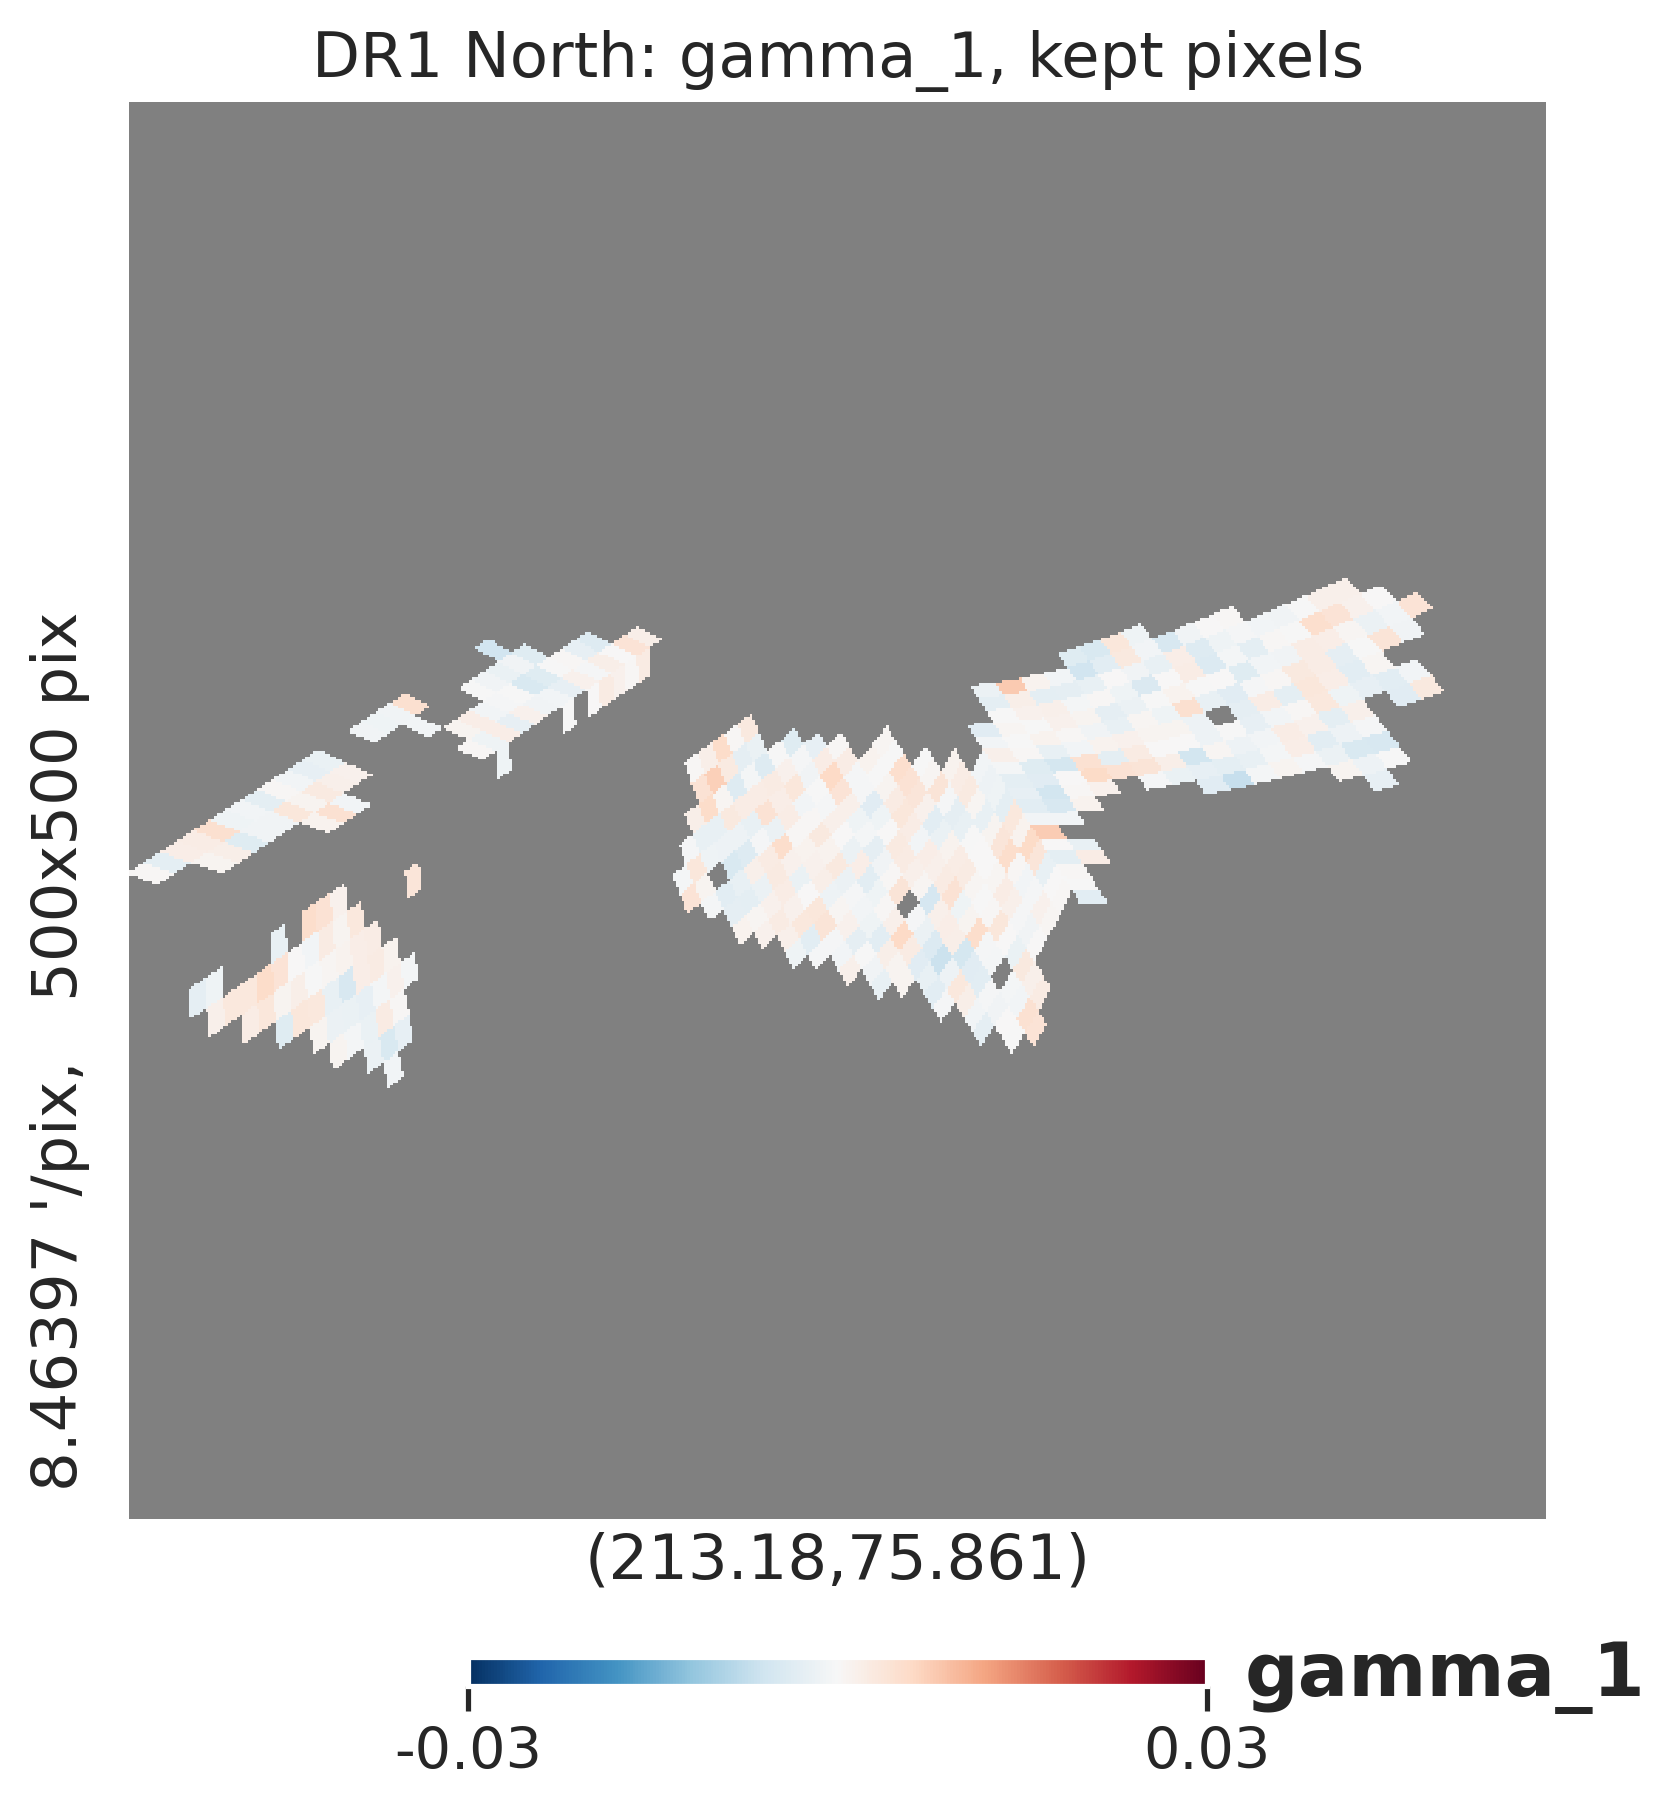

In [12]:
plot_map = np.where(mask, map_gamma1, hp.UNSEEN)
hp.gnomview(plot_map, rot=(lon_c[0], lat_c[0]), xsize=500, reso=2.2 * radius_deg * 60 / 500, cmap='RdBu_r',
            min=-0.03, max=0.03, title=f'{field_label}: gamma_1, kept pixels', unit='gamma_1')
plt.show()

## QML

Mask, noise variance and $\ell_{\max}$ are compile-time constants of the C++ library, so each run (with and without
the cut) gets a private copy of `cpp/` in `data/{field}/cpp_{tag}` and its own build. The Fisher matrix and $y_\ell$
are cached on disk; with the matrix-free conjugate-gradient solver the run time hardly depends on the number of
pixels (TR1 South took about 12 minutes).

In [13]:
def run_qml(tag, sel, sel_path, noise_var_q):
    # Builds the C++ for mask sel and noise_var_q, computes the Fisher matrix and y_ell if not cached
    fisher_path = f'{data_dir}/Fisher_matrix_{field}_N{n_side}_lmax{l_max_full}_maps{num_maps}_{tag}_nv{noise_var_q:.4e}.dat'
    y_path = f'{data_dir}/y_ell_{field}_N{n_side}_lmax{l_max_full}_maps{num_maps}_{tag}_nv{noise_var_q:.4e}.dat'
    if not (os.path.exists(fisher_path) and os.path.exists(y_path)):
        cpp_dir = f'{data_dir}/cpp_{tag}'
        shutil.copytree(f'{root_filepath}/cpp', cpp_dir, dirs_exist_ok=True, ignore=shutil.ignore_patterns('build*'))
        generate_constants_h(n_side, sel, noise_var_q, num_maps, f'{cpp_dir}/detail/constants.h', l_max=l_max_full)
        build_dir = f'{cpp_dir}/build-release'
        subprocess.run(['cmake', '-S', cpp_dir, '-B', build_dir, '-DCMAKE_BUILD_TYPE=Release'], check=True, capture_output=True)
        subprocess.run(['cmake', '--build', build_dir, '--target', 'QMLShearLib', '-j'], check=True, capture_output=True)
        lib = CppLib(f'{build_dir}/libQMLShearLib.so', sel_path, cl_file_path)
        start = time.time()
        if not os.path.exists(fisher_path):
            lib.compute_fisher_matrix(fisher_path)
        lib.compute_power_spectrum(*map_paths[tag], y_path)
        print(f'QML {tag}: {time.time() - start:,.0f} s')
    return fisher_path, y_path


def qml_bandpowers(fisher_path, y_path):
    # Binned QML: drop the EB block, symmetrise, bin F and y before inverting. Returns EE, BB (noise kept) and covariance
    F = np.loadtxt(fisher_path)
    F = np.delete(np.delete(F, np.s_[n_ell_full: 2 * n_ell_full], axis=0), np.s_[n_ell_full: 2 * n_ell_full], axis=1)
    F = (F + F.T) / 2
    y = np.delete(np.loadtxt(y_path), np.s_[n_ell_full: 2 * n_ell_full], axis=0)
    cov = np.linalg.inv(bin_matrix_EB @ F @ bin_matrix_EB.T)
    c = cov @ (bin_matrix_EB @ y)
    return c[:n_bands], c[n_bands:], cov


qml_files = {'cut': run_qml('cut', mask, mask_filepath, noise_var),
             'nocut': run_qml('nocut', mask_nocut, mask_nocut_filepath, noise_var_nocut)}
cl_EE_QML, cl_BB_QML, inv_fisher_QML = qml_bandpowers(*qml_files['cut'])
cov_EE_EE_QML = inv_fisher_QML[:n_bands, :n_bands]
cov_BB_BB_QML = inv_fisher_QML[n_bands:, n_bands:]
qml_nocut_EE, qml_nocut_BB, qml_nocut_cov = qml_bandpowers(*qml_files['nocut'])

## NaMaster (pseudo-$C_\ell$)

On the kept pixels, with its Gaussian covariance from the fiducial signal plus noise.

In [14]:
field_mask = nmt.NmtField(mask, None, spin=2, lmax=bins.lmax)
wsp = nmt.NmtWorkspace()
wsp.compute_coupling_matrix(field_mask, field_mask, bins)
covar_wsp = nmt.NmtCovarianceWorkspace.from_fields(field_mask, field_mask, field_mask, field_mask)

cl_EE, cl_zero = pow_spec.cl_EE, np.zeros_like(pow_spec.cl_EE)
spectra = [cl_EE + cl_noise, cl_zero, cl_zero, cl_zero + cl_noise]
covar_22_22 = nmt.gaussian_covariance(covar_wsp, 2, 2, 2, 2, spectra, spectra, spectra, spectra,
                                      wsp, wb=wsp).reshape([n_bands, 4, n_bands, 4])
cov_EE_EE_PCl = covar_22_22[:, 0, :, 0]
cov_BB_BB_PCl = covar_22_22[:, 3, :, 3]

field_shear = nmt.NmtField(mask, [map_gamma1, map_gamma2], lmax=bins.lmax)
cl_EE_PCl, cl_BB_PCl = wsp.decouple_cell(nmt.compute_coupled_cell(field_shear, field_shear))[[0, 3]]

## heracles on the catalogue

As for TR1 South: the catalogue is mapped directly (all tomographic bins together) and decoupled with heracles' mixing
matrices from the weight-map spectrum at twice the resolution, on the same bandpowers. It runs on all galaxies (no
cut) and on the galaxies in kept pixels only. Each run gives the spectra with the shot noise kept (`debias=False`, to
compare like for like with QML and NaMaster, which keep it) and with it subtracted (`debias=True`, for the with/without
cut comparison). heracles only uses a catalogue's visibility map for galaxy positions, not shears, so none is set here.

In [15]:
def heracles_bandpowers(sel=None):
    # heracles on the field's tiles (only galaxies in pixels sel if given). Returns {debias: (EE, BB)}
    def catalogue():
        cat = dr1_tools.ParquetTileCatalog(tiles, method, keep_pixels=sel, n_side=n_side)
        cat.fsky = (mask_nocut if sel is None else sel).mean()
        return {1: cat}

    mapper = heracles.healpy.HealpixMapper(n_side, l_max_full)
    fields = {
        'SHE': heracles.Shears(mapper, 'SHE_RA', 'SHE_DEC', '-SHE_E1_CORRECTED', 'SHE_E2_CORRECTED', 'SHE_WEIGHT', mask='WHT'),
        'WHT': heracles.Weights(mapper, 'SHE_RA', 'SHE_DEC', 'SHE_WEIGHT'),
    }
    alms = heracles.transform(fields, heracles.map_catalogs(fields, catalogue()))
    mapper2 = heracles.healpy.HealpixMapper(2 * n_side, 2 * l_max_full)
    fields2 = {'WHT': heracles.Weights(mapper2, 'SHE_RA', 'SHE_DEC', 'SHE_WEIGHT')}
    cls2 = heracles.angular_power_spectra(heracles.transform(fields2, heracles.map_catalogs(fields2, catalogue())))
    inv_mms = heracles.invert_mixing_matrix(
        heracles.mixing_matrices(fields, cls2, l1max=l_max_full, l2max=l_max_full, bins=ell_bp_edges))
    out = {}
    for debias in (False, True):
        cls = heracles.angular_power_spectra(alms, include=[('SHE', 'SHE')], debias=debias)
        deconv = heracles.apply_mixing_matrix(heracles.binned(cls, ell_bp_edges), inv_mms, lmax=l_max_full)
        key = ('SHE', 'SHE', 1, 1)
        out[debias] = (bins.bin_cell(np.array(deconv[key][0, 0])[: bins.lmax + 1]),
                       bins.bin_cell(np.array(deconv[key][1, 1])[: bins.lmax + 1]))
    return out


her_path = f'{data_dir}/heracles_bandpowers.npz'
if os.path.exists(her_path):
    h = np.load(her_path)
    her_all, her_kept = {False: tuple(h['all_biased']), True: tuple(h['all_debiased'])}, \
                        {False: tuple(h['kept_biased']), True: tuple(h['kept_debiased'])}
else:
    start = time.time()
    her_all = heracles_bandpowers()
    her_kept = heracles_bandpowers(mask)
    np.savez(her_path, all_biased=her_all[False], all_debiased=her_all[True],
             kept_biased=her_kept[False], kept_debiased=her_kept[True])
    print(f'heracles: {time.time() - start:.0f} s')
# The main comparison uses heracles on the full catalogue with the noise kept, as for TR1 South
cl_EE_heracles, cl_BB_heracles = her_all[False]

## Precision: NaMaster / QML error bars

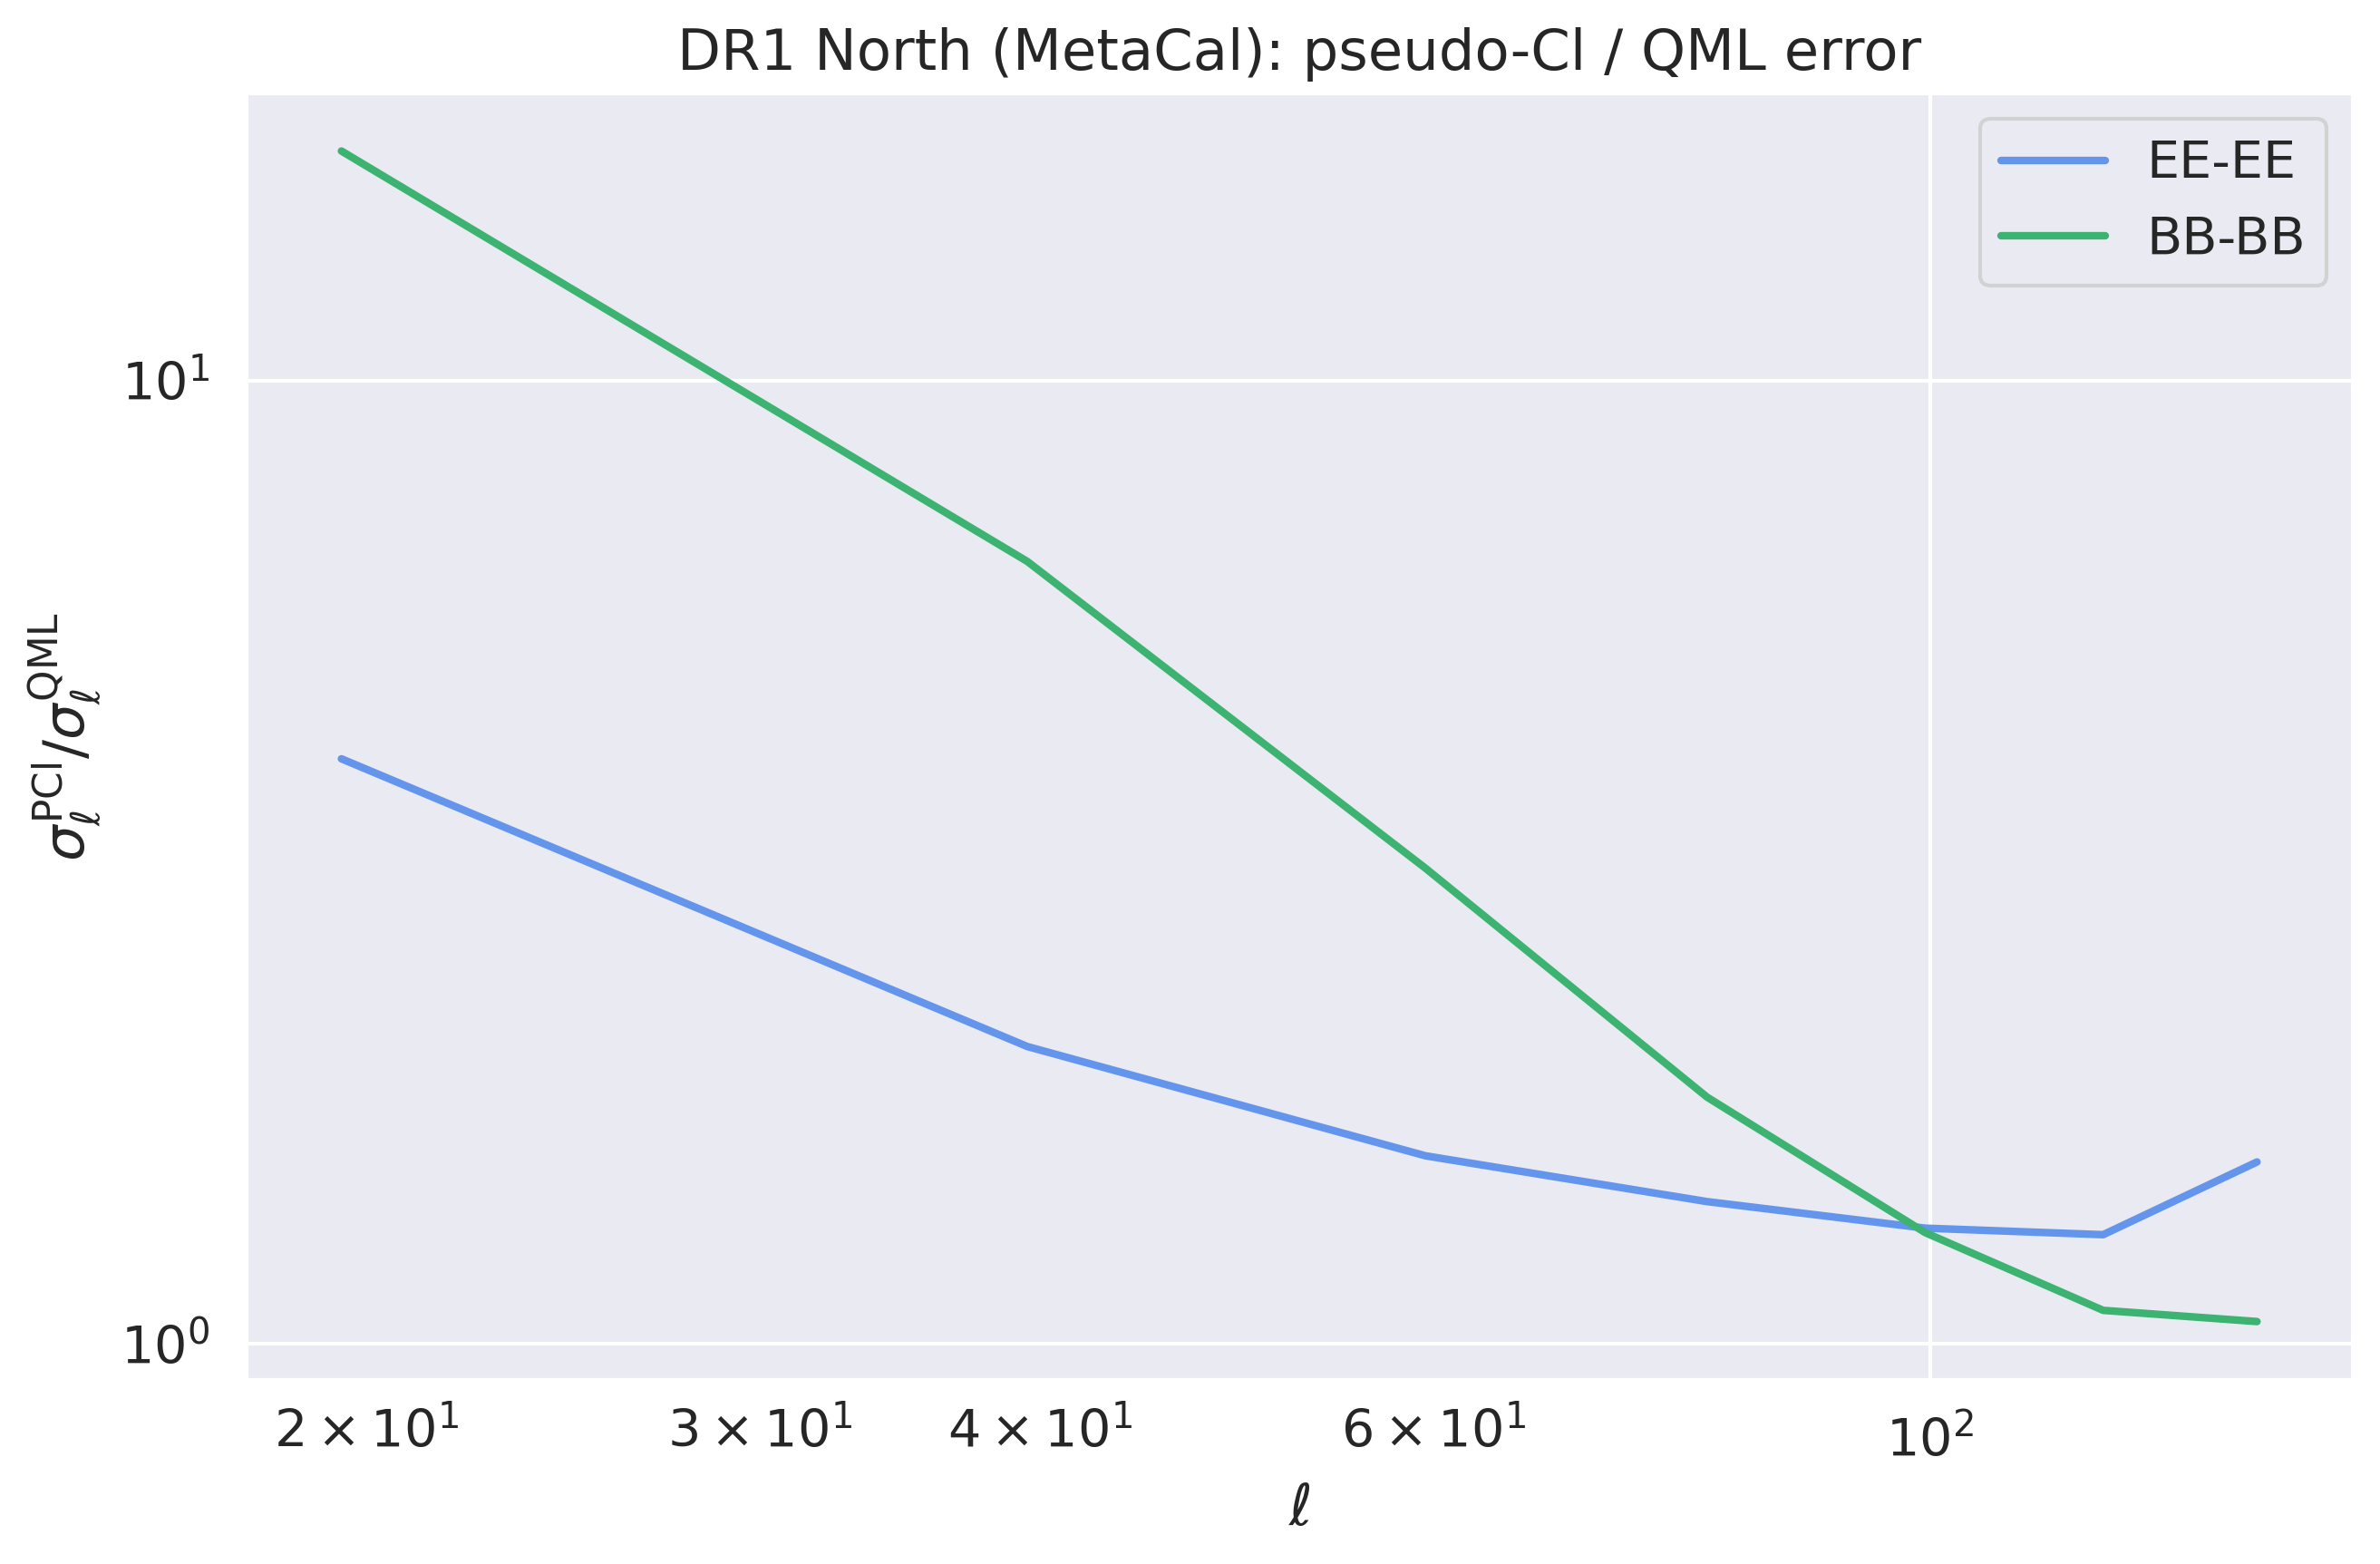

In [16]:
sig_EE_QML, sig_BB_QML = np.sqrt(np.diag(cov_EE_EE_QML)), np.sqrt(np.diag(cov_BB_BB_QML))
sig_EE_PCl, sig_BB_PCl = np.sqrt(np.diag(cov_EE_EE_PCl)), np.sqrt(np.diag(cov_BB_BB_PCl))
ratio_EE, ratio_BB = sig_EE_PCl / sig_EE_QML, sig_BB_PCl / sig_BB_QML

fig, ax = plt.subplots(figsize=(9, 6))
ax.loglog(ell_bp, ratio_EE, c='cornflowerblue', lw=2, label='EE-EE')
ax.loglog(ell_bp, ratio_BB, c='mediumseagreen', lw=2, label='BB-BB')
ax.set_xlabel(r'$\ell$')
ax.set_ylabel(r'$\sigma_{\ell}^{\mathrm{PCl}} / \sigma_{\ell}^{\mathrm{QML}}$')
ax.set_title(f'{field_label} ({method_label}): pseudo-Cl / QML error')
ax.legend()
plt.tight_layout()
fig.savefig(f'{fig_dir}/sigma.png', dpi=200, bbox_inches='tight')
plt.show()

## E- and B-mode spectra

The three estimators on the same bandpowers, shot noise kept. The dashed line is the fiducial signal (with pixel
window) plus noise for $EE$, and the noise level for $BB$; both are drawn only over the bandpower range, $\ell\ge10$.

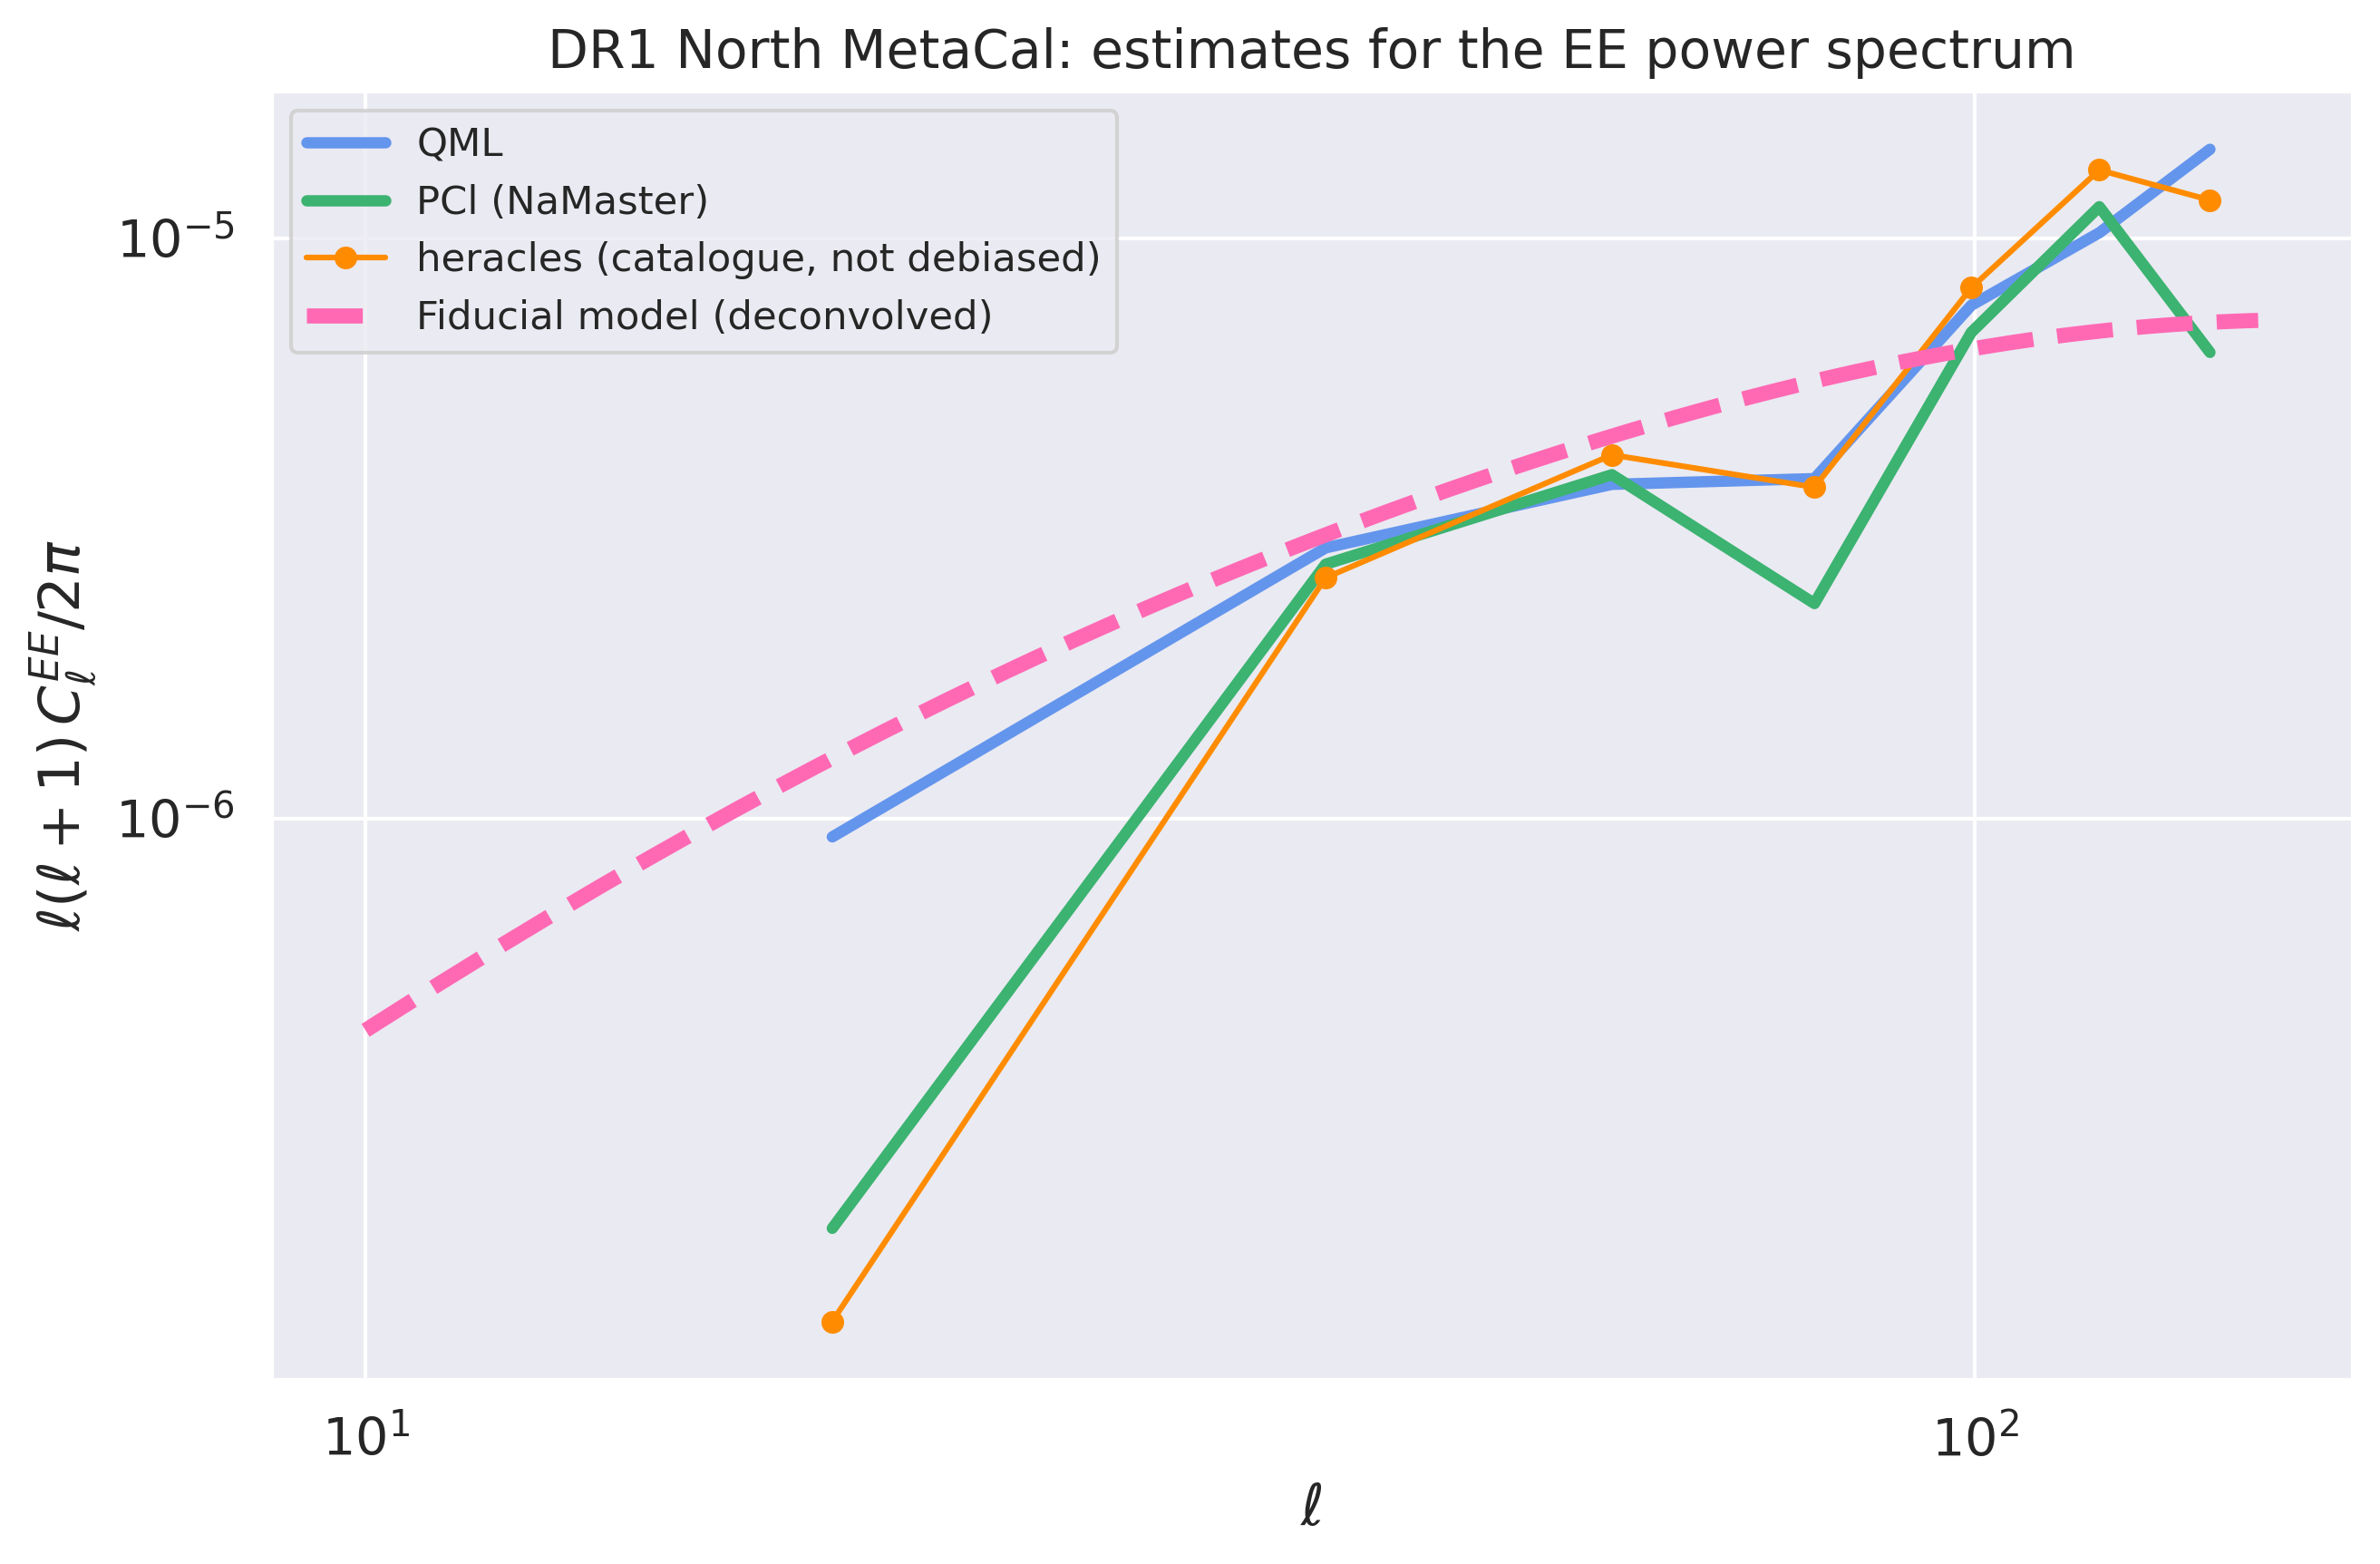

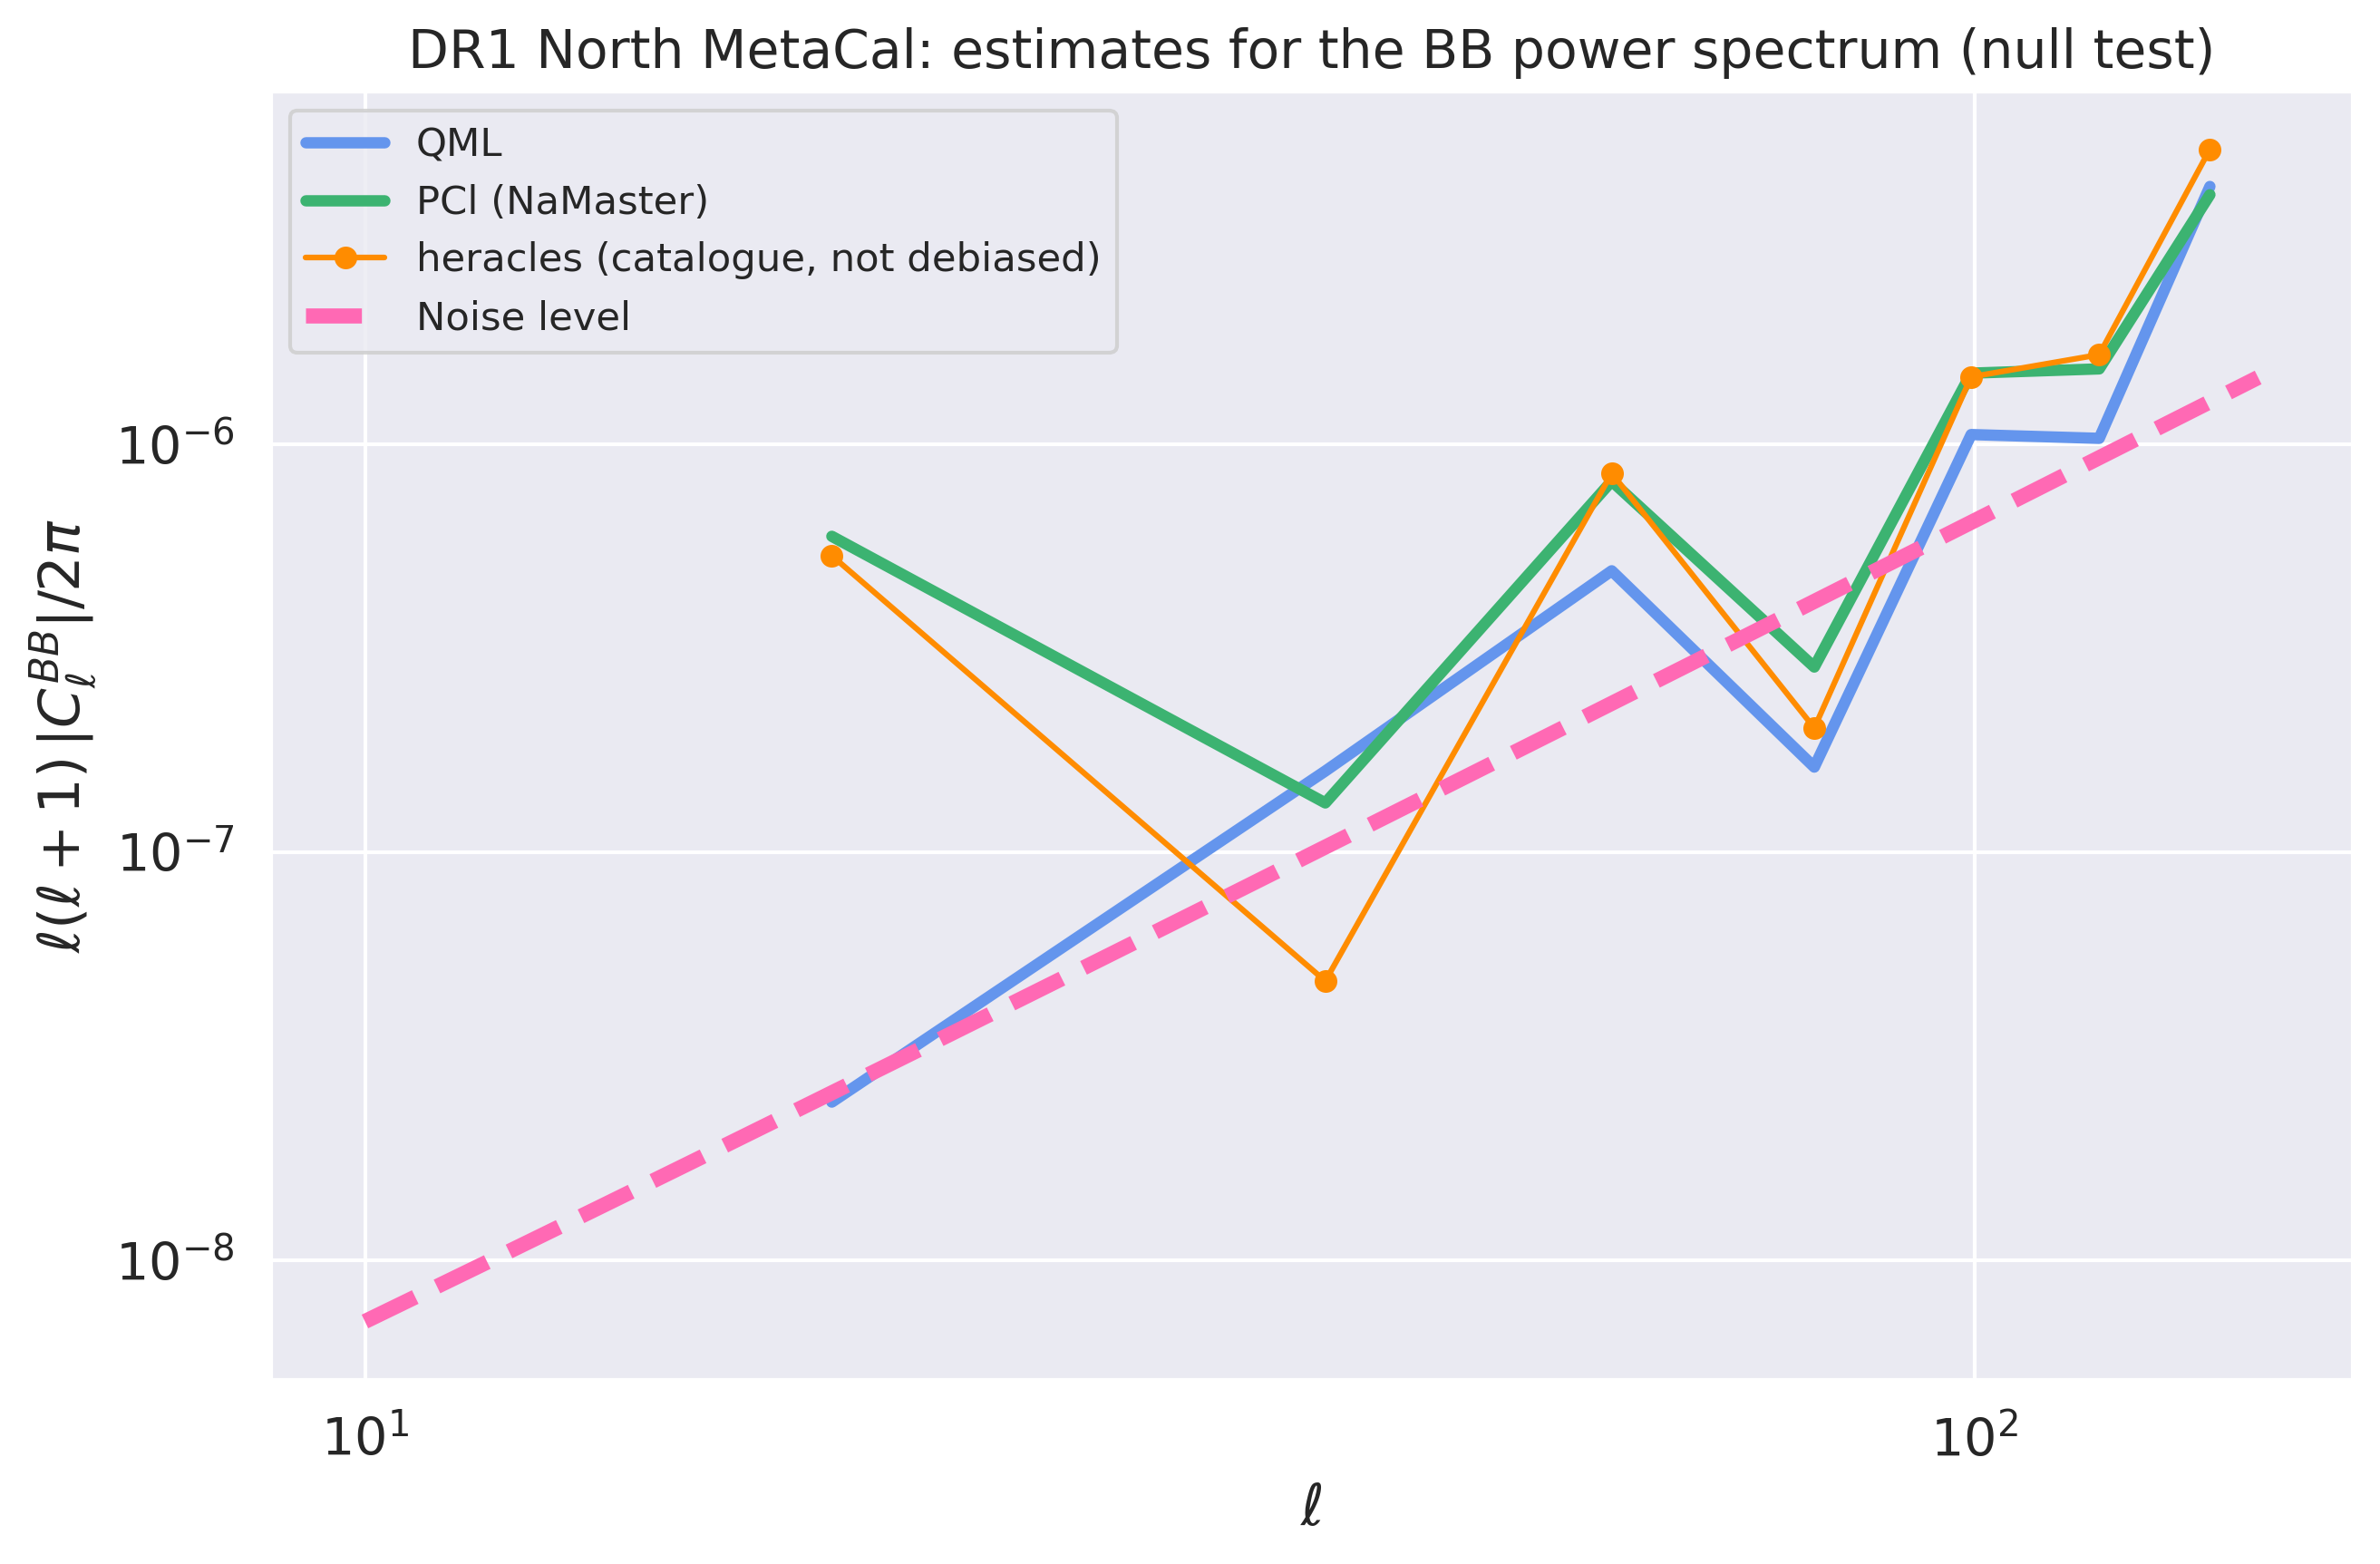

In [17]:
for spec, cls_q, cl_p, cl_h, theory, theory_label in [
        ('EE', cl_EE_QML, cl_EE_PCl, cl_EE_heracles, cl_EE_signal_pw[ells_plot] + cl_noise, 'Fiducial model (deconvolved)'),
        ('BB', cl_BB_QML, cl_BB_PCl, cl_BB_heracles, np.full(len(ells_plot), cl_noise), 'Noise level')]:
    fig, ax = plt.subplots(figsize=(9, 6))
    f = ell_bp * (ell_bp + 1) / (2 * np.pi)
    a = np.abs if spec == 'BB' else (lambda x: x)
    ax.loglog(ell_bp, f * a(cls_q), lw=3, c='cornflowerblue', label='QML')
    ax.loglog(ell_bp, f * a(cl_p), lw=3, c='mediumseagreen', label='PCl (NaMaster)')
    ax.loglog(ell_bp, f * a(cl_h), 'o-', lw=1.5, ms=5, c='darkorange', label='heracles (catalogue, not debiased)')
    ax.loglog(ells_plot, ells_plot * (ells_plot + 1) * theory / (2 * np.pi), lw=4, ls='--', c='hotpink', label=theory_label)
    title = 'estimates for the EE power spectrum' if spec == 'EE' else 'estimates for the BB power spectrum (null test)'
    ax.set_title(f'{field_label} {method_label}: {title}', fontsize=14)
    ax.set_xlabel(r'$\ell$')
    ax.set_ylabel(r'$\ell (\ell + 1) \, C_{\ell}^{EE} / 2 \pi$' if spec == 'EE' else r'$\ell (\ell + 1) \, |C_{\ell}^{BB}| / 2 \pi$')
    ax.legend(loc='upper left', fontsize='x-small')
    plt.tight_layout()
    fig.savefig(f'{fig_dir}/{spec.lower()}.png', dpi=200, bbox_inches='tight')
    plt.show()

### With error bars, noise removed

The same bandpowers with the shot noise `cl_noise` subtracted (the white-noise level QML's covariance assumes), and
error bars from the QML binned Fisher matrix and NaMaster's Gaussian covariance.

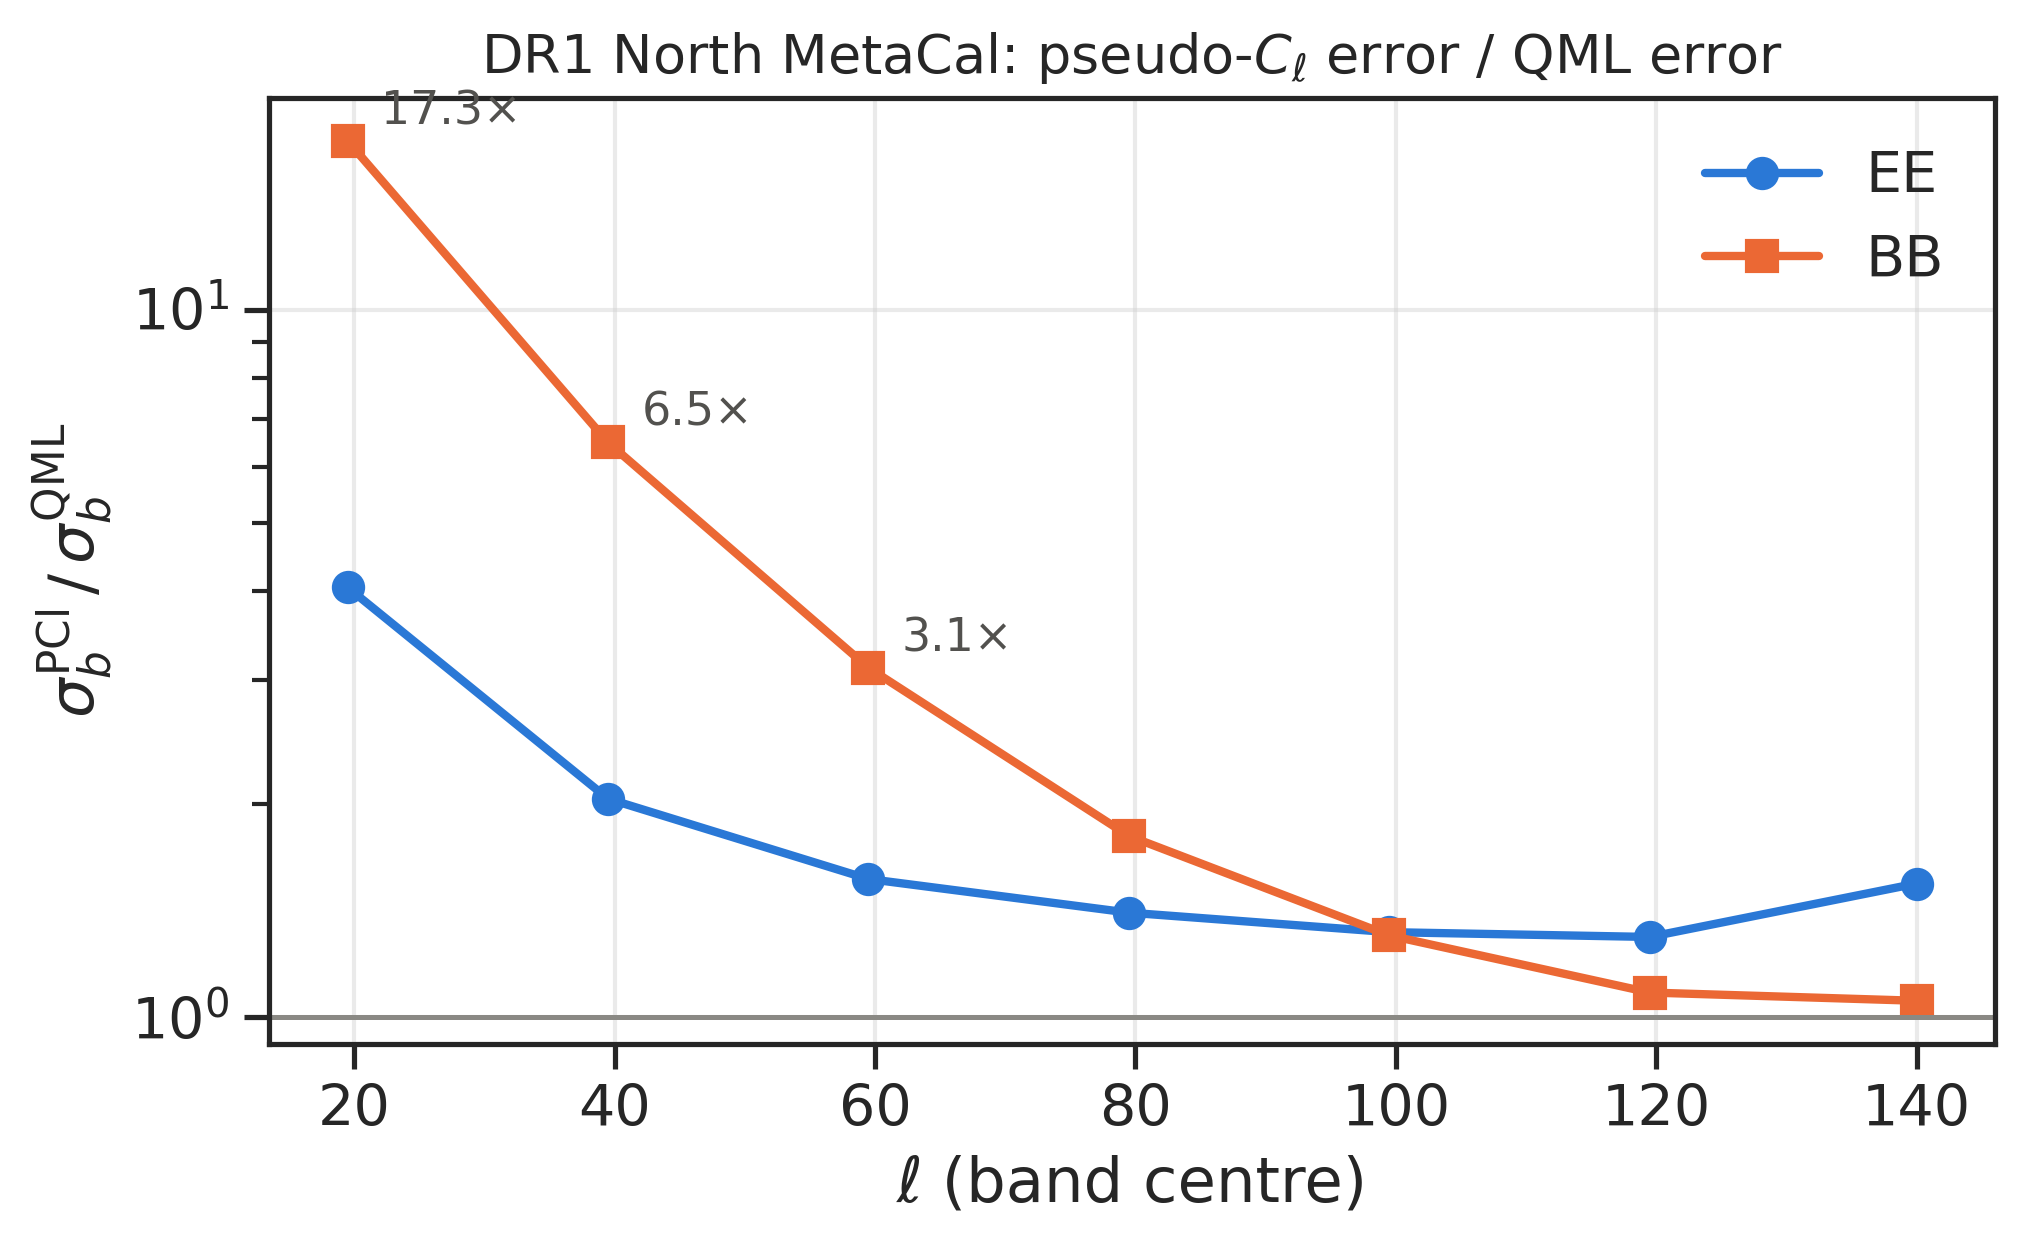

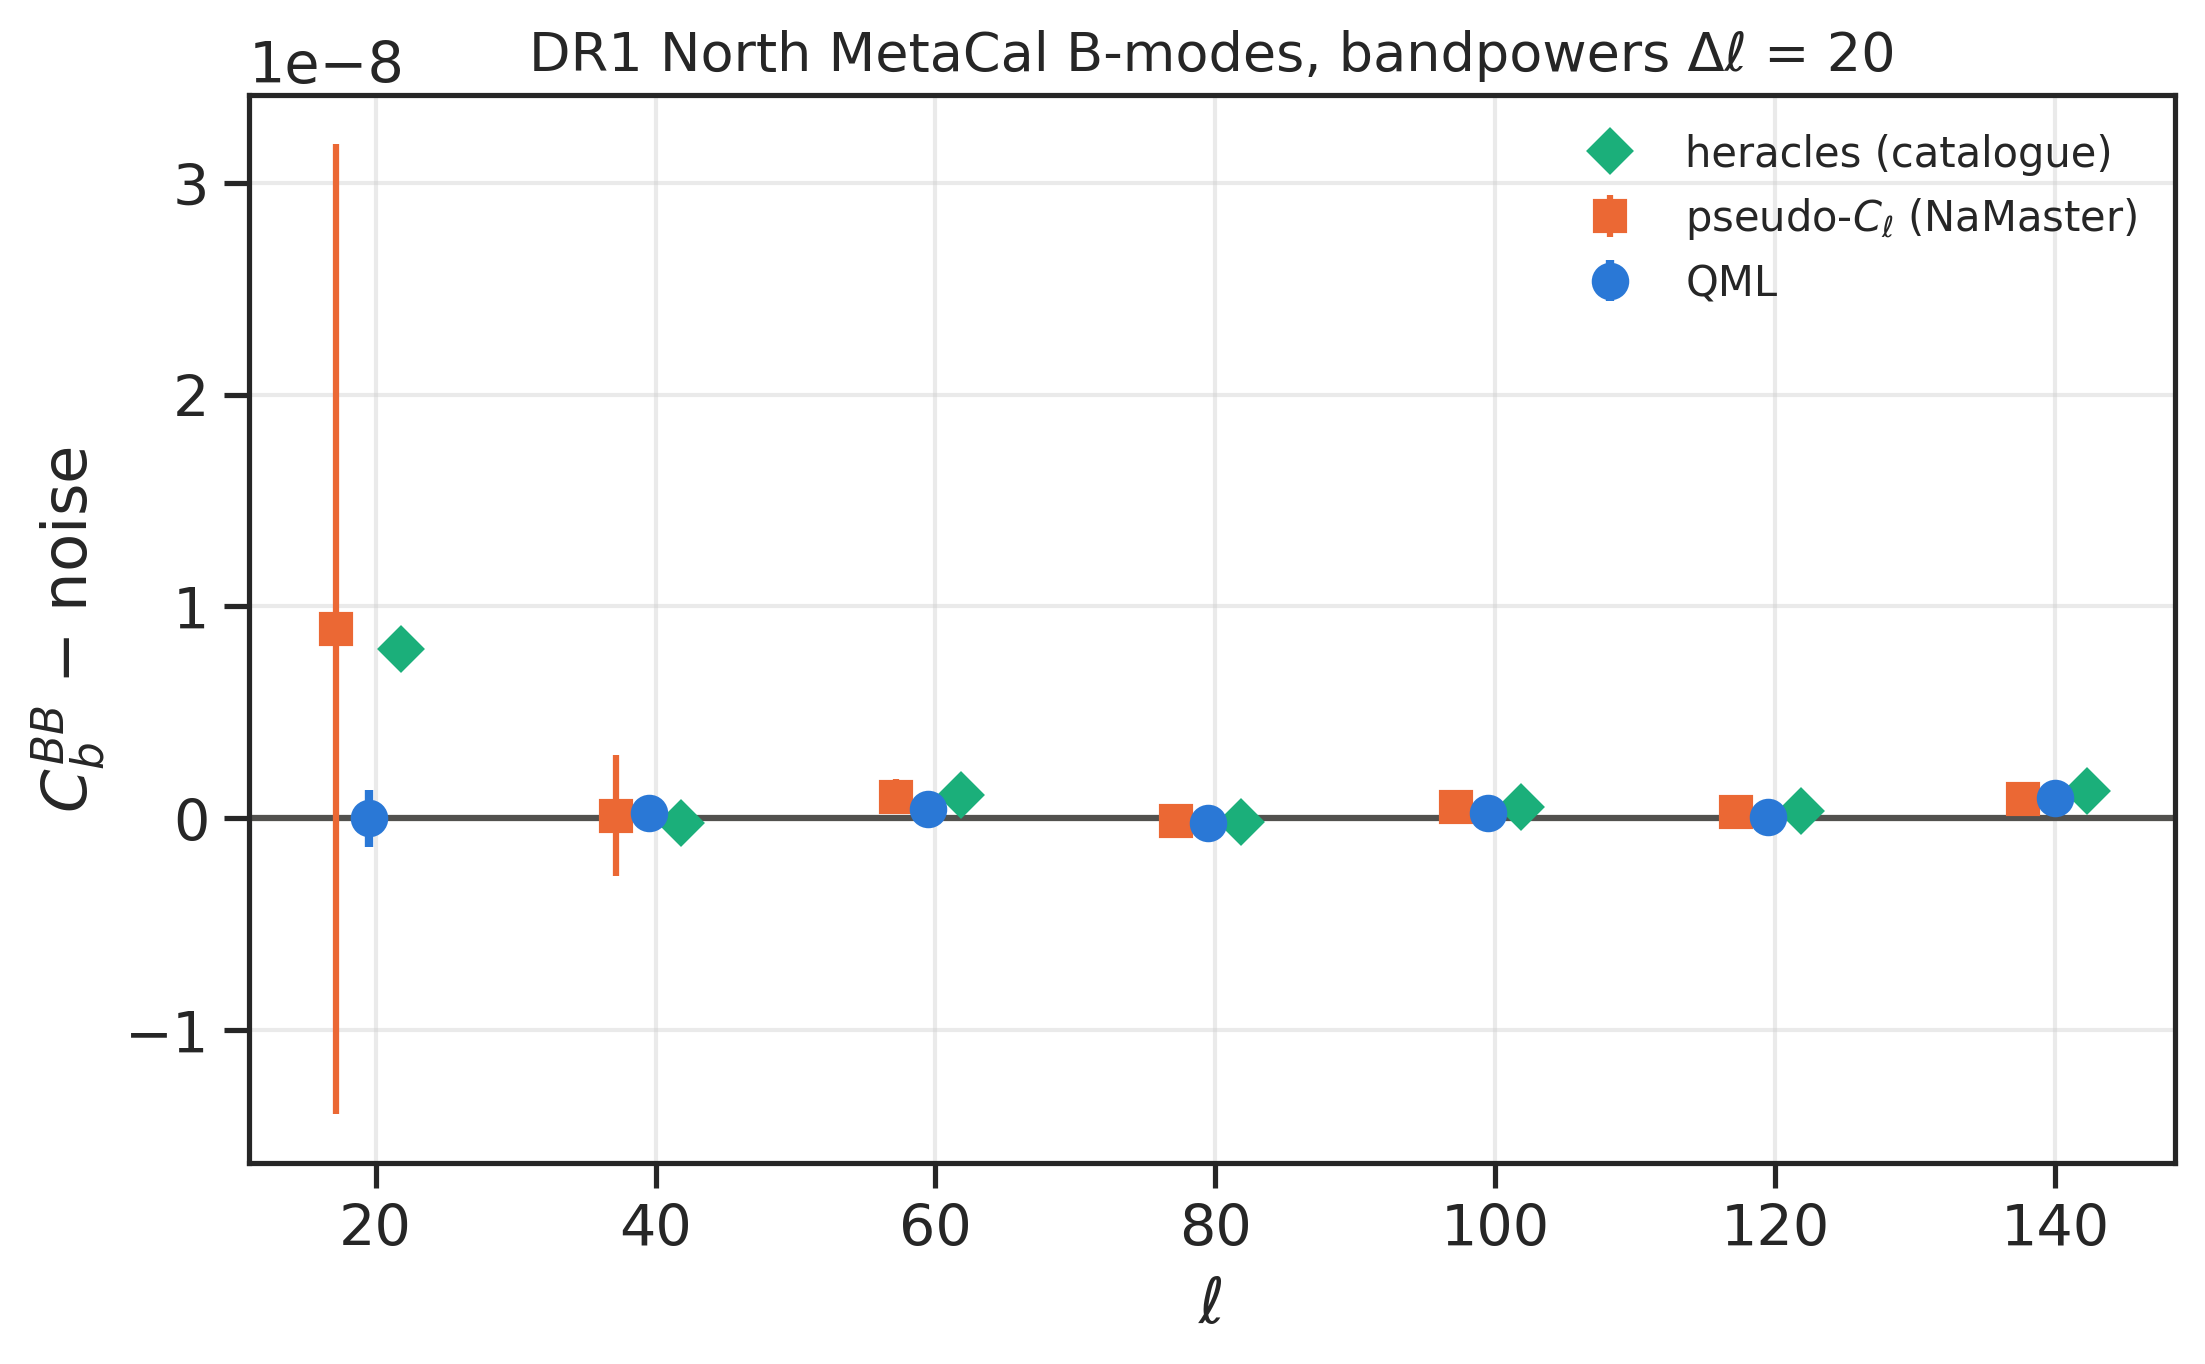

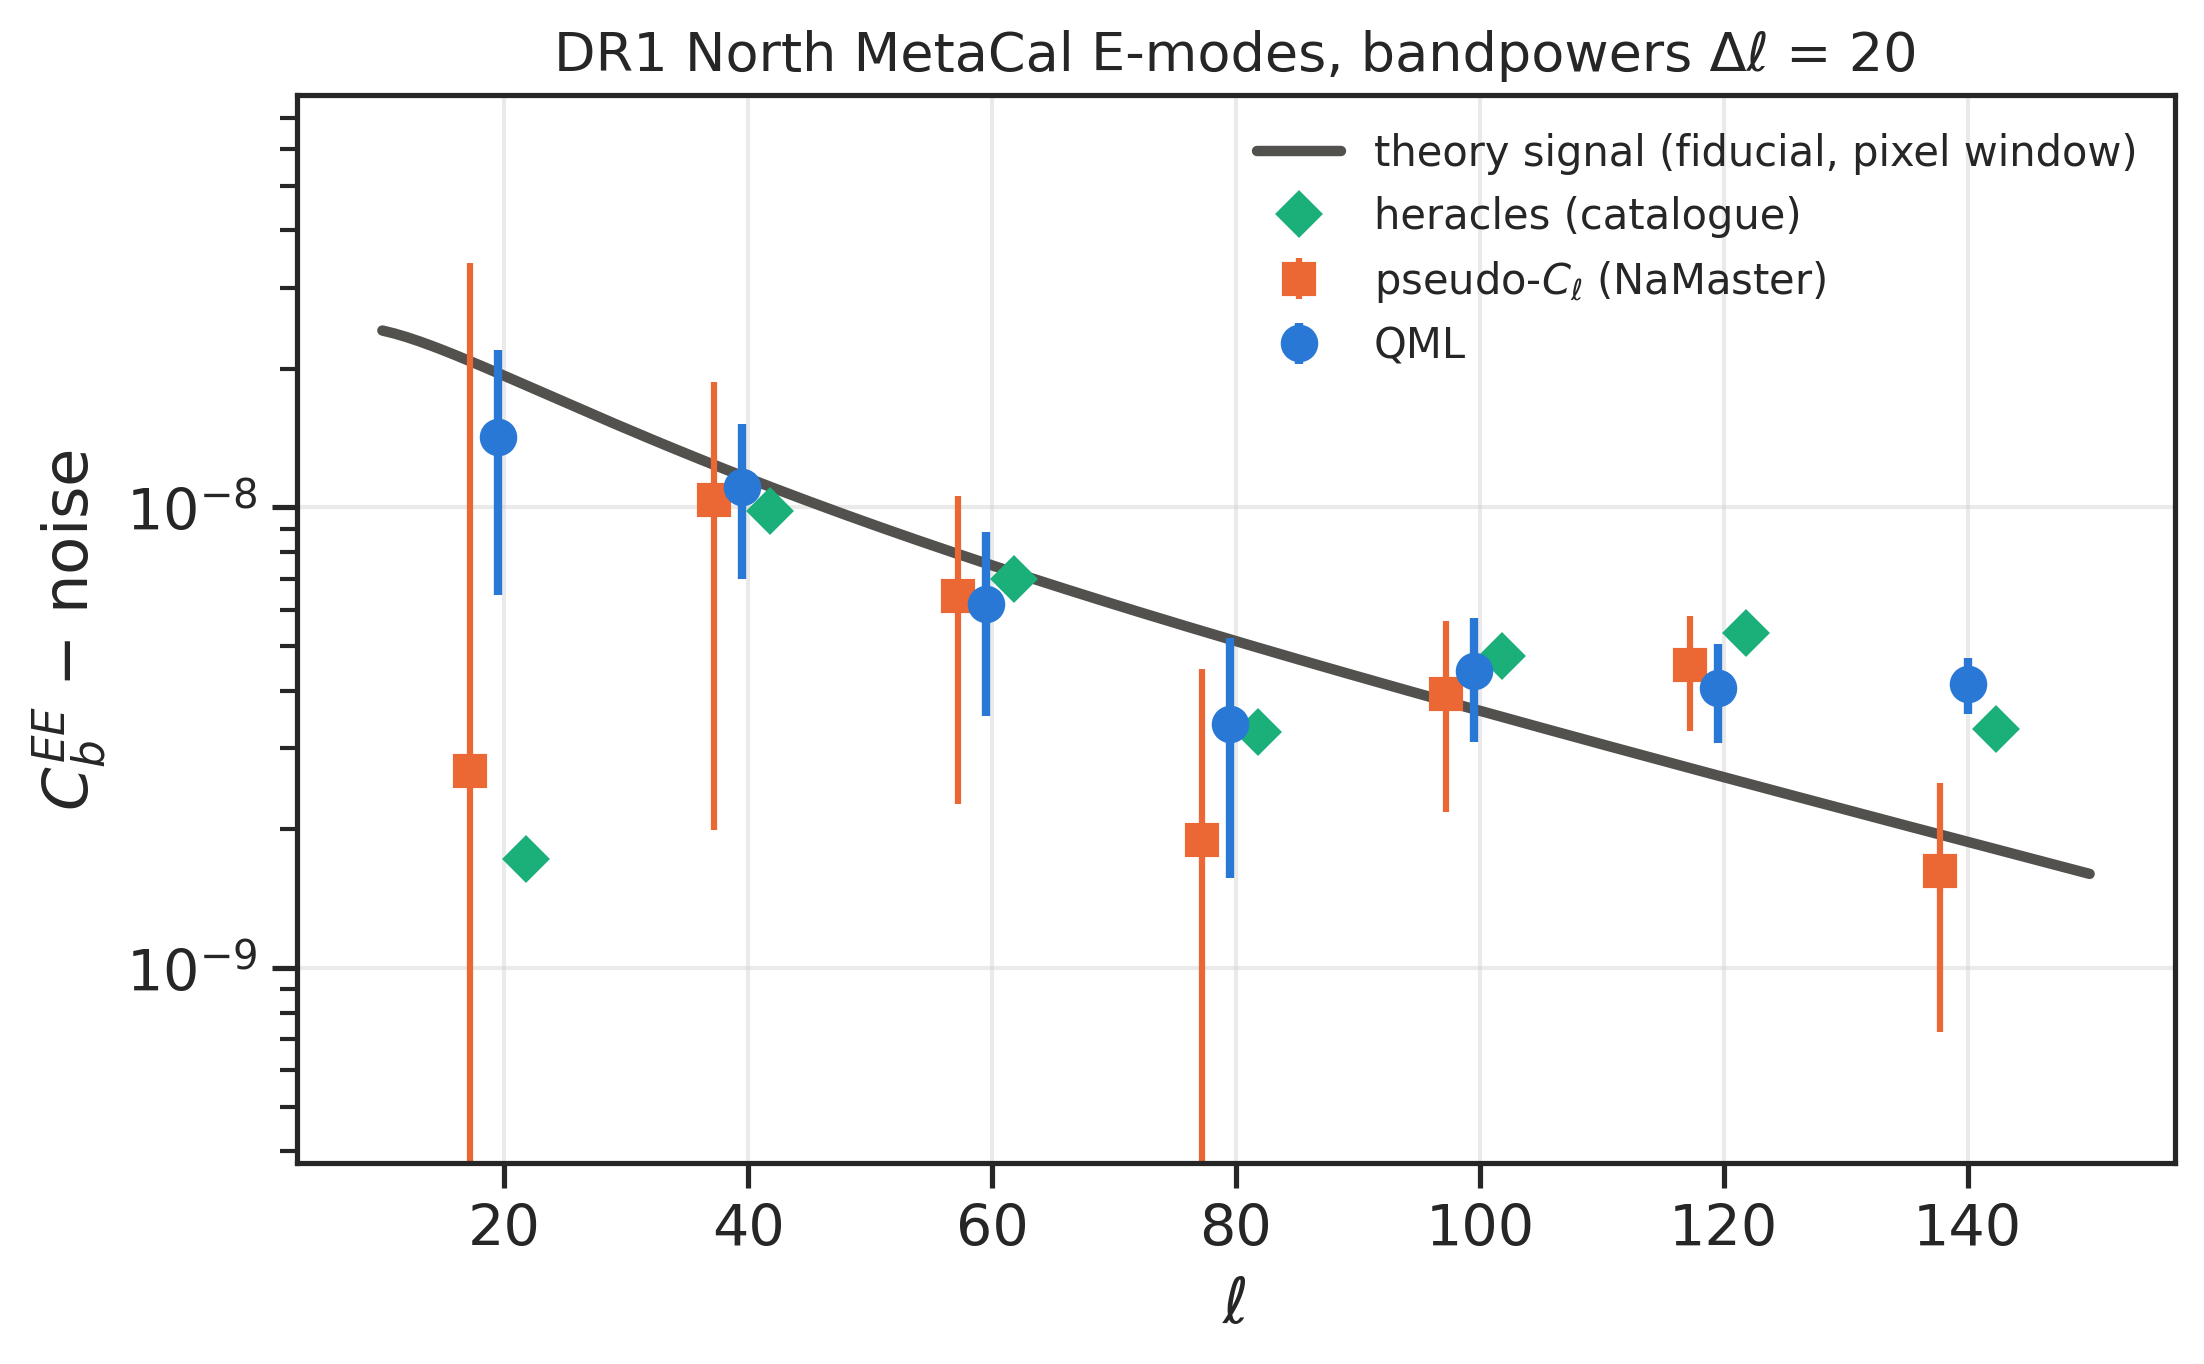

In [18]:
with sns.axes_style('ticks'):
    fig, ax = plt.subplots(figsize=(7, 4.4))
    ax.semilogy(ell_bp, ratio_EE, 'o-', color=BLUE, lw=2, ms=7, label='EE')
    ax.semilogy(ell_bp, ratio_BB, 's-', color=ORANGE, lw=2, ms=7, label='BB')
    for x, r in list(zip(ell_bp, ratio_BB))[:3]:
        ax.annotate(f'{r:.1f}×', (x, r), xytext=(8, 4), textcoords='offset points', fontsize=11, color=INK)
    ax.axhline(1, color='#8a8984', lw=1.2)
    ax.set_xlabel('ℓ (band centre)')
    ax.set_ylabel(r'$\sigma_b^{\rm PCl}\,/\,\sigma_b^{\rm QML}$')
    ax.set_title(f'{field_label} {method_label}: pseudo-$C_\\ell$ error / QML error', fontsize=13)
    ax.grid(alpha=0.4)
    ax.legend(frameon=False)
    fig.tight_layout()
    fig.savefig(f'{fig_dir}/fig1_precision.png', dpi=200, bbox_inches='tight')
    plt.show()

    theory_b = bins.bin_cell(cl_EE_signal_pw[: bins.lmax + 1])
    for spec, cl_q, cl_p, cl_h, sig_q, sig_p, name in [
            ('BB', cl_BB_QML, cl_BB_PCl, cl_BB_heracles, sig_BB_QML, sig_BB_PCl, 'fig2_bmodes'),
            ('EE', cl_EE_QML, cl_EE_PCl, cl_EE_heracles, sig_EE_QML, sig_EE_PCl, 'fig3_emodes')]:
        fig, ax = plt.subplots(figsize=(7.6, 4.8))
        if spec == 'EE':
            ax.plot(ells_plot, cl_EE_signal_pw[ells_plot], color=INK, lw=2.5, label='theory signal (fiducial, pixel window)')
            ax.set_yscale('log')
            ax.set_ylim(0.2 * theory_b.min(), 4 * theory_b.max())
        else:
            ax.axhline(0, color=INK, lw=1.5)
        ax.plot(ell_bp + 2.3, cl_h - cl_noise, 'D', color=GREEN, ms=7, label='heracles (catalogue)')
        ax.errorbar(ell_bp - 2.3, cl_p - cl_noise, sig_p, fmt='s', color=ORANGE, ms=7, elinewidth=1.5,
                    label=r'pseudo-$C_\ell$ (NaMaster)')
        ax.errorbar(ell_bp, cl_q - cl_noise, sig_q, fmt='o', color=BLUE, ms=8, elinewidth=2, label='QML')
        ax.set_xlabel('ℓ')
        ax.set_ylabel(f'$C_b^{{{spec}}}$ − noise')
        ax.set_title(f'{field_label} {method_label} {spec[0]}-modes, bandpowers Δℓ = {bandpower_width}', fontsize=13)
        ax.grid(alpha=0.4)
        ax.legend(loc='best', frameon=False, fontsize=10)
        fig.tight_layout()
        fig.savefig(f'{fig_dir}/{name}.png', dpi=200, bbox_inches='tight')
        plt.show()

## With and without the noisy pixels

QML and heracles on all pixels with galaxies (open markers) and on the kept pixels (filled). Both are shown with the
noise removed: heracles debiased, and QML minus the white-noise level its own covariance assumes. So $EE$ is compared
with the signal theory and $BB$ with zero. Error bars are QML's.

- If **QML moves a lot while heracles barely moves**, the problem is QML's uniform-noise assumption: heracles' weighting
  already copes with sparse pixels.
- If **heracles also moves**, the removed pixels carry something genuinely different, and the cut matters for any
  estimator.

QML, no cut  EE vs signal theory: chi2 = 399431.5 / 7 (PTE 0);   BB null test: chi2 = 1292284.0 / 7 (PTE 0)
QML, cut     EE vs signal theory: chi2 =     23.8 / 7 (PTE 0.0012);   BB null test: chi2 =     85.5 / 7 (PTE 1e-15)


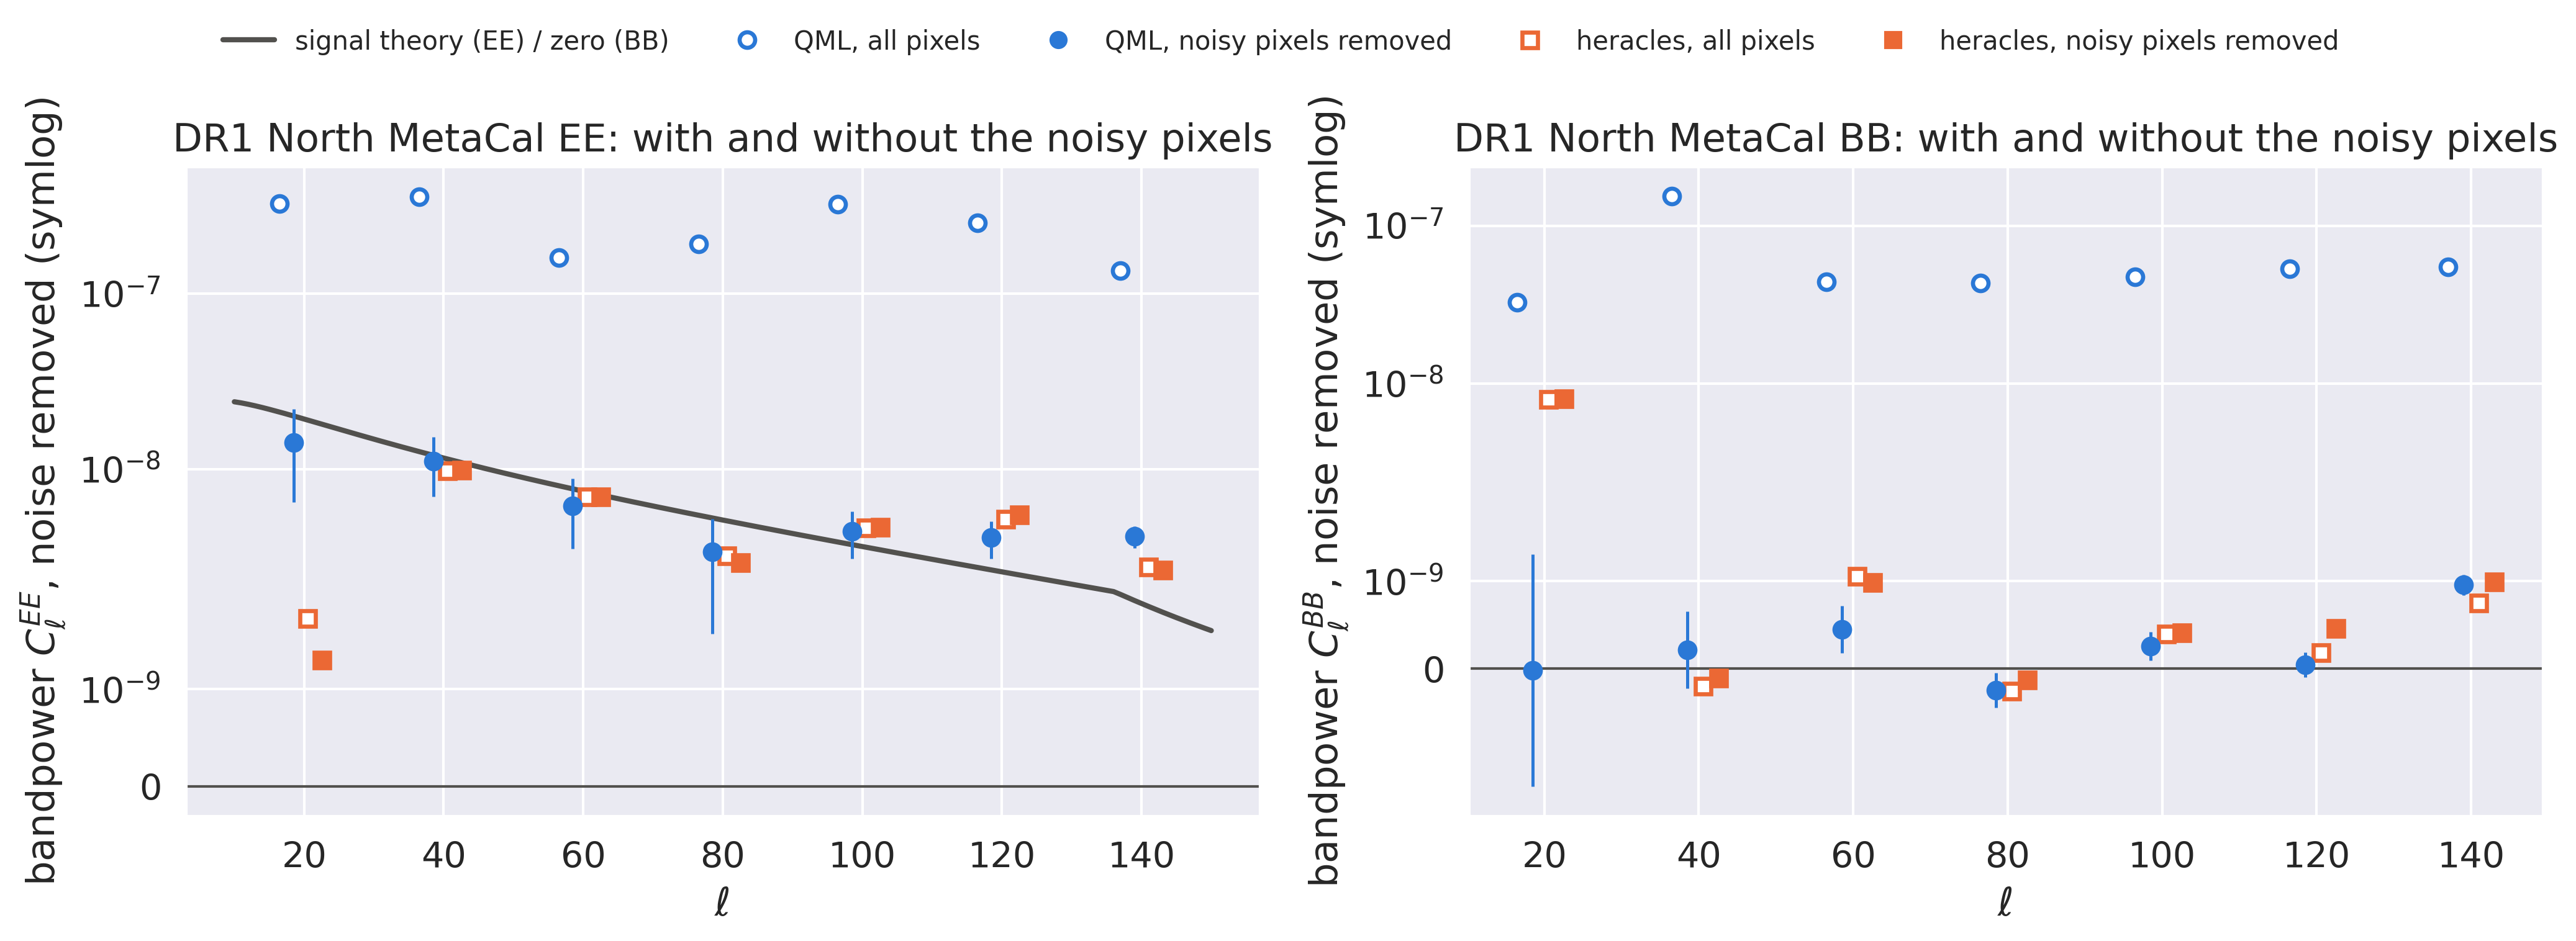

In [19]:
def qml_signal(EE, BB, noise_var_q):
    N_model = noise_var_q * 4 * np.pi / n_pix   # the white noise level QML's covariance assumes
    return EE - N_model, BB - N_model


qml_cut = (*qml_signal(cl_EE_QML, cl_BB_QML, noise_var), inv_fisher_QML)
qml_nocut = (*qml_signal(qml_nocut_EE, qml_nocut_BB, noise_var_nocut), qml_nocut_cov)
her_nocut, her_cut = her_all[True], her_kept[True]
theory_signal_b = bins.bin_cell(cl_EE_signal_pw[: bins.lmax + 1])


def chi2_pte(d, cov):
    x2 = d @ np.linalg.solve(cov, d)
    return x2, chi2_dist.sf(x2, len(d))


for label, (EE, BB, cov) in [('QML, no cut', qml_nocut), (f'QML, cut', qml_cut)]:
    x2E, pE = chi2_pte(EE - theory_signal_b, cov[:n_bands, :n_bands])
    x2B, pB = chi2_pte(BB, cov[n_bands:, n_bands:])
    print(f'{label:<12} EE vs signal theory: chi2 = {x2E:8.1f} / {n_bands} (PTE {pE:.2g});   '
          f'BB null test: chi2 = {x2B:8.1f} / {n_bands} (PTE {pB:.2g})')

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
dx = 2.0
for ax, idx, spec in [(axes[0], 0, 'EE'), (axes[1], 1, 'BB')]:
    if spec == 'EE':
        ax.plot(ells_plot, cl_EE_signal_pw[ells_plot], color=INK, lw=2, zorder=1)
    ax.axhline(0, color=INK, lw=1, zorder=1)
    for (EE, BB, cov), filled, shift in [(qml_nocut, False, -1.5 * dx), (qml_cut, True, -0.5 * dx)]:
        sig = np.sqrt(np.abs(np.diag(cov)))[idx * n_bands: (idx + 1) * n_bands]
        ax.errorbar(ell_bp + shift, (EE, BB)[idx], sig, fmt='o', ms=6, color=BLUE, mfc=BLUE if filled else 'white',
                    mew=1.6, elinewidth=1.2, capsize=0, zorder=3)
    for vals, filled, shift in [(her_nocut, False, 0.5 * dx), (her_cut, True, 1.5 * dx)]:
        ax.plot(ell_bp + shift, vals[idx], 's', ms=6, color=ORANGE, mfc=ORANGE if filled else 'white', mew=1.6, zorder=3)
    ax.set_yscale('symlog', linthresh=2e-9, linscale=1.0)
    ax.set_xlabel('ℓ')
    ax.set_ylabel(f'bandpower $C_\\ell^{{{spec}}}$, noise removed (symlog)')
    ax.set_title(f'{field_label} {method_label} {spec}: with and without the noisy pixels')
handles = [Line2D([], [], color=INK, lw=2, label='signal theory (EE) / zero (BB)'),
           Line2D([], [], marker='o', ls='', color=BLUE, mfc='white', mew=1.6, label='QML, all pixels'),
           Line2D([], [], marker='o', ls='', color=BLUE, label='QML, noisy pixels removed'),
           Line2D([], [], marker='s', ls='', color=ORANGE, mfc='white', mew=1.6, label='heracles, all pixels'),
           Line2D([], [], marker='s', ls='', color=ORANGE, label='heracles, noisy pixels removed')]
fig.legend(handles=handles, loc='upper center', ncol=5, bbox_to_anchor=(0.5, 1.03), frameon=False, fontsize=10)
fig.tight_layout(rect=(0, 0, 1, 0.95))
fig.savefig(f'{fig_dir}/cut_effect.png', dpi=200, bbox_inches='tight')
plt.show()

## Numbers

Error ratios, the $B$-mode null test (noise removed, against zero) and the $E$-mode $\chi^2$ against the fiducial
signal, all from the kept pixels.

In [20]:
bb_q, bb_h = cl_BB_QML - cl_noise, cl_BB_heracles - cl_noise
print('band centre             ', np.round(ell_bp, 1))
print('sigma PCl/QML, EE       ', np.round(ratio_EE, 1))
print('sigma PCl/QML, BB       ', np.round(ratio_BB, 1))
print('QML BB / sigma_QML      ', np.round(bb_q / sig_BB_QML, 1))
print('heracles BB / sigma_QML ', np.round(bb_h / sig_BB_QML, 1))
print('QML EE - N - theory / sigma', np.round((cl_EE_QML - cl_noise - theory_signal_b) / sig_EE_QML, 1))
# Sign check: with the wrong e1 sign this would be ~0.5
print('QML (BB - N) / EE theory', np.round(bb_q / theory_signal_b, 2))

x2, pte = chi2_pte(bb_q, cov_BB_BB_QML)
print(f'QML BB vs zero, all {n_bands} bands: chi2 = {x2:.1f}, PTE = {pte:.2g}')
low = ell_bp_end <= 110
x2, pte = chi2_pte(bb_q[low], cov_BB_BB_QML[np.ix_(low, low)])
print(f'QML BB vs zero, l = {ell_bp_ini[0]}-{ell_bp_end[low][-1] - 1} ({low.sum()} bands): chi2 = {x2:.1f}, PTE = {pte:.2g}')
x2, pte = chi2_pte(cl_EE_QML - cl_noise - theory_signal_b, cov_EE_EE_QML)
print(f'QML EE vs signal theory: chi2 = {x2:.1f} / {n_bands}, PTE = {pte:.2g}')
print(f'Effective density {avg_gal_den:.1f}/arcmin^2, sigma_e = {np.sqrt(sigma_e2):.3f}')

band centre              [ 19.5  39.5  59.5  79.5  99.5 119.5 140. ]
sigma PCl/QML, EE        [4.  2.  1.6 1.4 1.3 1.3 1.5]
sigma PCl/QML, BB        [17.3  6.5  3.1  1.8  1.3  1.1  1.1]
QML BB / sigma_QML       [-0.   0.5  1.7 -1.2  1.6  0.3  8.1]
heracles BB / sigma_QML  [ 6.  -0.5  4.  -1.   3.1  2.2 10.8]
QML EE - N - theory / sigma [-0.7 -0.2 -0.5 -1.   0.6  1.5  3.9]
QML (BB - N) / EE theory [-0.    0.02  0.06 -0.05  0.07  0.02  0.51]
QML BB vs zero, all 7 bands: chi2 = 85.5, PTE = 1e-15
QML BB vs zero, l = 10-109 (5 bands): chi2 = 7.0, PTE = 0.22
QML EE vs signal theory: chi2 = 23.8 / 7, PTE = 0.0012
Effective density 16.3/arcmin^2, sigma_e = 0.279


## Save a results summary

In [21]:
summary_path = f'{data_dir}/results_summary_{field}_N{n_side}_lmax{l_max_full}_maps{num_maps}_neff{neff_min_frac:g}.npz'
np.savez(
    summary_path,
    n_side=n_side, l_max_full=l_max_full, num_maps=num_maps, neff_min_frac=neff_min_frac, f_sky=f_sky,
    n_pix_mask=mask.sum(), n_pix_nocut=mask_nocut.sum(), density_arcmin2=avg_gal_den, sigma_e=np.sqrt(sigma_e2),
    noise_var=noise_var, noise_var_nocut=noise_var_nocut, cl_noise=cl_noise,
    ell_bp=ell_bp, ell_bp_edges=ell_bp_edges, ells=ells, cl_EE_theory=pow_spec.cl_EE, cl_EE_theory_pw=cl_EE_signal_pw,
    cl_EE_QML=cl_EE_QML, cl_BB_QML=cl_BB_QML, cov_QML=inv_fisher_QML,
    cl_EE_PCl=cl_EE_PCl, cl_BB_PCl=cl_BB_PCl, cov_EE_EE_PCl=cov_EE_EE_PCl, cov_BB_BB_PCl=cov_BB_BB_PCl,
    cl_EE_heracles=cl_EE_heracles, cl_BB_heracles=cl_BB_heracles,
    qml_nocut_EE=qml_nocut[0], qml_nocut_BB=qml_nocut[1], qml_nocut_cov=qml_nocut[2],
    qml_cut_EE=qml_cut[0], qml_cut_BB=qml_cut[1], qml_cut_cov=qml_cut[2],
    her_nocut_EE=her_nocut[0], her_nocut_BB=her_nocut[1], her_cut_EE=her_cut[0], her_cut_BB=her_cut[1],
    mask=mask, mask_nocut=mask_nocut, neff_ratio=neff_ratio,
)
print('saved', summary_path)

saved /workspaces/QML/DR1/data/metacal/north/results_summary_north_N64_lmax150_maps10_neff0.5.npz
